# Predição de Doença Cardíaca (*Heart Failure Prediction*) — Análise Exploratória de Dados (EDA)

**Fonte:** [Kaggle · fedesoriano/heart-failure-prediction](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction) · [UCI Machine Learning Repository — Heart Disease (id 45)](https://archive.ics.uci.edu/dataset/45/heart+disease)

## Sobre o conjunto de dados

O conjunto de dados **Heart Failure Prediction** (frequentemente referenciado como *Heart Disease Dataset*) consolida registros clínicos e ergométricos de quatro instituições hospitalares clássicas do repositório UCI (após a remoção de 272 registros duplicados provenientes da base *Statlog*):

1. **Hungarian Institute of Cardiology, Budapeste** — 293 registros (linhas `0` a `292`);
2. **University Hospital, Zurique e Basileia, Suíça** — 123 registros (linhas `293` a `415`);
3. **V.A. Medical Center, Long Beach, Califórnia** — 200 registros (linhas `416` a `615`);
4. **Cleveland Clinic Foundation, Ohio** — 302 registros (linhas `616` a `917`).

No total, a tabela em [`data/heart.csv`](data/heart.csv) contém **918 pacientes × 12 colunas**: **11 atributos preditivos** (5 numéricos contínuos, 1 numérico binário e 5 categóricos) e a **variável-alvo binária** `HeartDisease` (`1` = presença de doença arterial coronariana com estreitamento luminal $> 50\%$ em pelo menos um vaso principal; `0` = ausência de doença).

## Objetivo deste notebook

Realizar uma exploração estatística e clínica completa da base antes da modelagem com **Redes Neurais Artificiais (MLP)**:

1. **Dicionário de dados e padronização terminológica** para o português (módulo [`traducao.py`](traducao.py));
2. **Auditoria de integridade e anomalias clínicas**: investigação de valores ausentes ocultos codificados como zero (`Cholesterol = 0` e `RestingBP = 0`), valores negativos em `Oldpeak` e o vínculo estrutural dessas anomalias com as coortes hospitalares de origem;
3. **Análise univariada**: distribuição da variável-alvo, frequência das variáveis categóricas e perfil distributivo (assimetria, curtose e *outliers* pelo critério de Tukey) das variáveis contínuas;
4. **Análise bivariada e testes de hipótese**: cruzamento de cada atributo com o diagnóstico de doença cardíaca ($\chi^2$, $V$ de Cramér, correlação ponto-bisserial $r_{pb}$, correlação de Spearman $\rho$ e teste de Mann-Whitney $U$), incluindo a demonstração do **Paradoxo de Simpson no colesterol sérico**;
5. **Análise multivariada e interações**: matrizes de correlação (bruta vs. saneada) e interações de segunda ordem entre sintomas, resposta eletrocardiográfica ao esforço, idade e sexo;
6. **Diretrizes práticas para Redes Neurais**: tradução direta dos achados exploratórios em decisões de pré-processamento, imputação com indicador de ausência (*missing indicator*), escalonamento e regularização.

> **Convenção visual:** mantendo o padrão dos trabalhos anteriores do projeto, toda figura é acompanhada da tabela exata que a originou, com separadores decimais em vírgula nos gráficos (módulo [`graficos.py`](graficos.py)).

## 1. Configuração e carregamento dos dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

from traducao import (
    COLUNAS, TIPOS, UNIDADES, traduzir_dataframe, dicionario_dados, rotulo, ordem_classes,
)
from graficos import (
    configurar_estilo, formatar_int, formatar_pct, formatar_num,
    tabela_frequencia, grafico_barras, distribuicao_categorica, distribuicao_numerica,
    resumo_estatistico_numerico, tabela_taxa, grafico_taxa, taxa_por_categoria,
    taxa_por_faixa, comparar_grupos_numerico, AZUL, AZUL_CLARO, CORAL, CINZA_OUTROS, TEXTO, TEXTO_SEC,
)

configurar_estilo()

In [2]:
CAMINHO = "data/heart.csv"
df_original = pd.read_csv(CAMINHO)

print(f"{formatar_int(df_original.shape[0])} linhas × {df_original.shape[1]} colunas")
display(df_original.head(8))

918 linhas × 12 colunas


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0


## 2. Dicionário de dados e tradução

A função `dicionario_dados()` do módulo [`traducao.py`](traducao.py) documenta os 12 atributos da base: nome original no CSV, identificador padronizado em português (`snake_case`), rótulo legível, natureza estatística, unidade clínica e descrição fisiológica. Em seguida, `traduzir_dataframe()` gera o DataFrame traduzido `df` utilizado ao longo da análise.

In [3]:
dicionario = dicionario_dados()
display(dicionario)

,Coluna original,Coluna (pt),Rótulo,Tipo,Unidade,Nº de classes,Descrição clínica
0,Age,idade,Idade (anos),numérica (contínua),anos,<NA>,"Idade do paciente no momento do exame, em anos."
1,Sex,sexo,Sexo,categórica (binária),—,2,"Sexo biológico do paciente (M = Masculino, F = Feminino)."
2,ChestPainType,tipo_dor_peito,Tipo de dor no peito,categórica (nominal),—,4,"Classificação clínica da dor torácica: ASY (Assintomática), NAP (Dor não anginosa), ATA (Angina atípica) ou TA (Angina típica)."
3,RestingBP,pressao_repouso,Pressão arterial em repouso (mmHg),numérica (contínua),mmHg,<NA>,Pressão arterial sistólica em repouso na admissão hospitalar (mmHg). Contém 1 registro igual a 0.
4,Cholesterol,colesterol,Colesterol sérico (mg/dL),numérica (contínua),mg/dL,<NA>,Colesterol sérico total (mg/dL). Contém 172 registros iguais a 0 (ausentes codificados como zero nas coortes da Suíça e de Long Beach VA).
5,FastingBS,glicemia_jejum,Glicemia em jejum,categórica (binária),> 120 mg/dL (binário),2,"Glicemia em jejum: 1 se > 120 mg/dL (indicativo de hiperglicemia/diabetes), 0 caso contrário (≤ 120 mg/dL)."
6,RestingECG,ecg_repouso,ECG em repouso,categórica (nominal),—,3,"Resultado do eletrocardiograma em repouso: Normal, ST (anomalia de onda ST-T: inversão de onda T e/ou elevação/depressão de ST > 0,05 mV) ou LVH (hipertrofia ventricular esquerda provável ou definitiva pelos critérios de Estes)."
7,MaxHR,freq_cardiaca_max,Frequência cardíaca máxima (bpm),numérica (contínua),bpm,<NA>,Frequência cardíaca máxima alcançada durante o teste ergométrico (entre 60 e 202 bpm).
8,ExerciseAngina,angina_exercicio,Angina induzida por exercício,categórica (binária),—,2,"Presença de angina induzida pelo exercício durante o teste ergométrico (Y = Sim, N = Não)."
9,Oldpeak,depressao_st,"Depressão do segmento ST (Oldpeak, mV)",numérica (contínua),mV (ou mm),<NA>,Depressão do segmento ST induzida pelo exercício em relação ao repouso (mV). Valores negativos (13 casos) indicam elevação do segmento ST.


In [4]:
df = traduzir_dataframe(df_original)
display(df.head(8))

,idade,sexo,tipo_dor_peito,pressao_repouso,colesterol,glicemia_jejum,ecg_repouso,freq_cardiaca_max,angina_exercicio,depressao_st,inclinacao_st,doenca_cardiaca
0,40,Masculino,Angina atípica (ATA),140,289,≤ 120 mg/dL (0),Normal,172,Não (N),0.0,Ascendente (Up),Sem doença (0)
1,49,Feminino,Dor não anginosa (NAP),160,180,≤ 120 mg/dL (0),Normal,156,Não (N),1.0,Plana (Flat),Com doença (1)
2,37,Masculino,Angina atípica (ATA),130,283,≤ 120 mg/dL (0),Anomalia de ST-T (ST),98,Não (N),0.0,Ascendente (Up),Sem doença (0)
3,48,Feminino,Assintomática (ASY),138,214,≤ 120 mg/dL (0),Normal,108,Sim (Y),1.5,Plana (Flat),Com doença (1)
4,54,Masculino,Dor não anginosa (NAP),150,195,≤ 120 mg/dL (0),Normal,122,Não (N),0.0,Ascendente (Up),Sem doença (0)
5,39,Masculino,Dor não anginosa (NAP),120,339,≤ 120 mg/dL (0),Normal,170,Não (N),0.0,Ascendente (Up),Sem doença (0)
6,45,Feminino,Angina atípica (ATA),130,237,≤ 120 mg/dL (0),Normal,170,Não (N),0.0,Ascendente (Up),Sem doença (0)
7,54,Masculino,Angina atípica (ATA),110,208,≤ 120 mg/dL (0),Normal,142,Não (N),0.0,Ascendente (Up),Sem doença (0)


## 3. Qualidade dos dados, ausentes ocultos e estrutura de coortes

### 3.1 Verificação estrutural (nulos explícitos e duplicatas)

Em uma inspeção puramente sintática (`isna()` e `duplicated()`), a base parece pronta para uso: **não há valores `NaN`, strings vazias ou marcadores `?`**, nem linhas duplicadas (mesmo desconsiderando a coluna-alvo).

In [5]:
resumo_estrutura = pd.DataFrame({
    "Tipo (pandas)": df.dtypes.astype(str),
    "Natureza": [TIPOS[en] for en in COLUNAS],
    "Não nulos": df.notna().sum().values,
    "Nulos explícitos (NaN)": df.isna().sum().values,
    "Valores distintos": [df[col].nunique() for col in df.columns],
}, index=pd.Index(df.columns, name="Atributo"))

duplicatas_totais = int(df.duplicated().sum())
duplicatas_features = int(df.drop(columns=["doenca_cardiaca"]).duplicated().sum())
print(f"Linhas duplicadas (todas as 12 colunas): {duplicatas_totais}")
print(f"Linhas duplicadas nos 11 atributos preditivos: {duplicatas_features}")
display(resumo_estrutura)

Linhas duplicadas (todas as 12 colunas): 0
Linhas duplicadas nos 11 atributos preditivos: 0


,Tipo (pandas),Natureza,Não nulos,Nulos explícitos (NaN),Valores distintos
Atributo,,,,,
idade,int64,numérica (contínua),918,0,50
sexo,str,categórica (binária),918,0,2
tipo_dor_peito,str,categórica (nominal),918,0,4
pressao_repouso,int64,numérica (contínua),918,0,67
colesterol,int64,numérica (contínua),918,0,222
glicemia_jejum,str,categórica (binária),918,0,2
ecg_repouso,str,categórica (nominal),918,0,3
freq_cardiaca_max,int64,numérica (contínua),918,0,119
angina_exercicio,str,categórica (binária),918,0,2


### 3.2 Auditoria de domínio clínico: zeros espúrios e valores negativos

Quando confrontamos os intervalos numéricos com a fisiologia humana, surgem **três fenômenos críticos** que impactam diretamente o treinamento de redes neurais:

1. **`colesterol == 0` em 172 pacientes (18,74% da base):** um ser humano vivo não pode ter $0\text{ mg/dL}$ de colesterol sérico total. Trata-se de **valores ausentes codificados como `0`** durante a integração histórica das bases do repositório UCI.
2. **`pressao_repouso == 0` em 1 paciente (0,11%, índice `449`):** pressão arterial sistólica igual a zero é incompatível com a vida. O paciente (homem, 55 anos, dor não anginosa, `doenca_cardiaca = 1`) também possui `colesterol = 0`, confirmando ausência de registro na admissão.
3. **`depressao_st < 0` em 13 pacientes (1,42%, entre $-2,6$ e $-0,1\text{ mV}$):** diferentemente dos zeros em pressão e colesterol, valores negativos de *Oldpeak* **não são erros de codificação**, mas registros em que houve *supradesnivelamento* (elevação) do segmento ST induzido pelo exercício em vez de infradesnivelamento (depressão) — um achado clínico real associado a isquemia transmural ou espasmo coronariano.

In [6]:
anomalias = pd.DataFrame([
    {
        "Condição investigada": "Colesterol sérico igual a zero (colesterol == 0)",
        "Significado clínico": "Valor ausente codificado como 0 (fisiologicamente impossível)",
        "Registros": int((df["colesterol"] == 0).sum()),
        "Percentual da base (%)": round((df["colesterol"] == 0).mean() * 100, 2),
        "Casos com doença (1)": int(((df["colesterol"] == 0) & (df["doenca_cardiaca"] == "Com doença (1)")).sum()),
        "Taxa de doença no grupo (%)": round(
            (df.loc[df["colesterol"] == 0, "doenca_cardiaca"] == "Com doença (1)").mean() * 100, 2
        ),
    },
    {
        "Condição investigada": "Pressão arterial em repouso igual a zero (pressao_repouso == 0)",
        "Significado clínico": "Valor ausente codificado como 0 (linha 449; também tem colesterol == 0)",
        "Registros": int((df["pressao_repouso"] == 0).sum()),
        "Percentual da base (%)": round((df["pressao_repouso"] == 0).mean() * 100, 2),
        "Casos com doença (1)": int(((df["pressao_repouso"] == 0) & (df["doenca_cardiaca"] == "Com doença (1)")).sum()),
        "Taxa de doença no grupo (%)": round(
            (df.loc[df["pressao_repouso"] == 0, "doenca_cardiaca"] == "Com doença (1)").mean() * 100, 2
        ),
    },
    {
        "Condição investigada": "Depressão de ST negativa (depressao_st < 0)",
        "Significado clínico": "Supradesnivelamento (elevação) do segmento ST no esforço",
        "Registros": int((df["depressao_st"] < 0).sum()),
        "Percentual da base (%)": round((df["depressao_st"] < 0).mean() * 100, 2),
        "Casos com doença (1)": int(((df["depressao_st"] < 0) & (df["doenca_cardiaca"] == "Com doença (1)")).sum()),
        "Taxa de doença no grupo (%)": round(
            (df.loc[df["depressao_st"] < 0, "doenca_cardiaca"] == "Com doença (1)").mean() * 100, 2
        ),
    },
    {
        "Condição investigada": "Registros 100% válidos (colesterol > 0 e pressao_repouso > 0)",
        "Significado clínico": "Medições fisiológicas completas",
        "Registros": int(((df["colesterol"] > 0) & (df["pressao_repouso"] > 0)).sum()),
        "Percentual da base (%)": round(((df["colesterol"] > 0) & (df["pressao_repouso"] > 0)).mean() * 100, 2),
        "Casos com doença (1)": int(
            ((df["colesterol"] > 0) & (df["pressao_repouso"] > 0) & (df["doenca_cardiaca"] == "Com doença (1)")).sum()
        ),
        "Taxa de doença no grupo (%)": round(
            (df.loc[(df["colesterol"] > 0) & (df["pressao_repouso"] > 0), "doenca_cardiaca"] == "Com doença (1)").mean() * 100, 2
        ),
    },
]).set_index("Condição investigada")

display(anomalias)

print("\nRegistro com pressao_repouso == 0 (índice 449):")
display(df.loc[[449]])


Registro com pressao_repouso == 0 (índice 449):


,Significado clínico,Registros,Percentual da base (%),Casos com doença (1),Taxa de doença no grupo (%)
Condição investigada,,,,,
Colesterol sérico igual a zero (colesterol == 0),Valor ausente codificado como 0 (fisiologicamente impossível),172,18.74,152,88.37
Pressão arterial em repouso igual a zero (pressao_repouso == 0),Valor ausente codificado como 0 (linha 449; também tem colesterol == 0),1,0.11,1,100.00
Depressão de ST negativa (depressao_st < 0),Supradesnivelamento (elevação) do segmento ST no esforço,13,1.42,9,69.23
Registros 100% válidos (colesterol > 0 e pressao_repouso > 0),Medições fisiológicas completas,746,81.26,356,47.72


,idade,sexo,tipo_dor_peito,pressao_repouso,colesterol,glicemia_jejum,ecg_repouso,freq_cardiaca_max,angina_exercicio,depressao_st,inclinacao_st,doenca_cardiaca
449,55,Masculino,Dor não anginosa (NAP),0,0,≤ 120 mg/dL (0),Normal,155,Não (N),1.5,Plana (Flat),Com doença (1)


### 3.3 Rastreamento por coorte hospitalar: por que `colesterol == 0` prevê doença cardíaca?

Ao inspecionar a posição das linhas no arquivo [`data/heart.csv`](data/heart.csv), descobre-se que os registros estão **concatenados na ordem exata das quatro bases originais do UCI**. Quando separamos os quatro blocos, a origem dos valores `colesterol == 0` e `depressao_st < 0` fica completamente explicada:

- **Bloco 1 — Hungria (`linhas 0..292`, $n = 293$):** $0\%$ de colesterol zero e $36,18\%$ de doença cardíaca;
- **Bloco 2 — Suíça (`linhas 293..415`, $n = 123$):** **100% dos pacientes (123 de 123)** têm `colesterol == 0`, 11 dos 13 casos de `depressao_st < 0` estão aqui, e **93,50% têm doença cardíaca**;
- **Bloco 3 — Long Beach VA (`linhas 416..615`, $n = 200$):** **24,50% dos pacientes (49 de 200)** têm `colesterol == 0`, inclui o único caso de `pressao_repouso == 0`, apenas $3,0\%$ são mulheres (hospital de veteranos militares) e **74,50% têm doença cardíaca**;
- **Bloco 4 — Cleveland (`linhas 616..917`, $n = 302$):** $0\%$ de colesterol zero e $45,70\%$ de doença cardíaca.

Portanto, os zeros de colesterol **não estão ausentes completamente ao acaso (MCAR)**: eles funcionam como uma **variável *proxy* oculta da coorte hospitalar** (especialmente a coorte suíça e a de veteranos, onde a prevalência de cardiopatia severa é altíssima). Em particular, nos 89 pacientes em que `colesterol == 0` ocorre junto com `glicemia_jejum > 120 mg/dL`, **88 pacientes (98,88%) possuem doença cardíaca**!

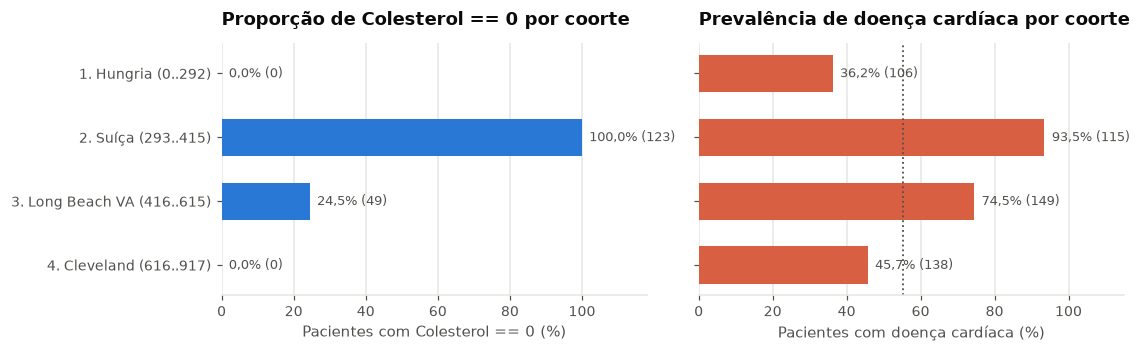

,Pacientes (n),Mulheres (%),Colesterol == 0 (n),Colesterol == 0 (%),Pressão == 0 (n),Oldpeak < 0 (n),Com doença (n),Prevalência de doença (%)
Coorte (intervalo de linhas),,,,,,,,
1. Hungria (0..292),293,27.30,0,0.0,0,0,106,36.18
2. Suíça (293..415),123,8.13,123,100.0,0,11,115,93.50
3. Long Beach VA (416..615),200,3.00,49,24.5,1,2,149,74.50
4. Cleveland (616..917),302,32.12,0,0.0,0,0,138,45.70


In [7]:
blocos = [
    ("1. Hungria (0..292)", df.iloc[0:293]),
    ("2. Suíça (293..415)", df.iloc[293:416]),
    ("3. Long Beach VA (416..615)", df.iloc[416:616]),
    ("4. Cleveland (616..917)", df.iloc[616:918]),
]

linhas_coorte = []
for nome_bloco, sub in blocos:
    n_sub = len(sub)
    c_zero = int((sub["colesterol"] == 0).sum())
    bp_zero = int((sub["pressao_repouso"] == 0).sum())
    st_neg = int((sub["depressao_st"] < 0).sum())
    fem = int((sub["sexo"] == "Feminino").sum())
    doentes = int((sub["doenca_cardiaca"] == "Com doença (1)").sum())
    linhas_coorte.append({
        "Coorte (intervalo de linhas)": nome_bloco,
        "Pacientes (n)": n_sub,
        "Mulheres (%)": round(fem / n_sub * 100, 2),
        "Colesterol == 0 (n)": c_zero,
        "Colesterol == 0 (%)": round(c_zero / n_sub * 100, 2),
        "Pressão == 0 (n)": bp_zero,
        "Oldpeak < 0 (n)": st_neg,
        "Com doença (n)": doentes,
        "Prevalência de doença (%)": round(doentes / n_sub * 100, 2),
    })

tab_coortes = pd.DataFrame(linhas_coorte).set_index("Coorte (intervalo de linhas)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.3), sharey=True)
y_pos = np.arange(len(tab_coortes))[::-1]
nomes = list(tab_coortes.index)

ax1.barh(y_pos, tab_coortes["Colesterol == 0 (%)"].values, color=AZUL, height=0.58)
ax1.set_yticks(y_pos, nomes)
ax1.set_xlim(0, 118)
ax1.grid(axis="y", visible=False)
ax1.set_title("Proporção de Colesterol == 0 por coorte")
ax1.set_xlabel("Pacientes com Colesterol == 0 (%)")
for p, v, n_c in zip(y_pos, tab_coortes["Colesterol == 0 (%)"].values, tab_coortes["Colesterol == 0 (n)"].values):
    ax1.text(v + 2, p, f"{formatar_pct(v)} ({n_c})", va="center", fontsize=8.5, color=TEXTO_SEC)

ax2.barh(y_pos, tab_coortes["Prevalência de doença (%)"].values, color=CORAL, height=0.58)
ax2.set_xlim(0, 115)
ax2.grid(axis="y", visible=False)
ax2.axvline((df["doenca_cardiaca"] == "Com doença (1)").mean() * 100, color=TEXTO_SEC, linestyle=":", linewidth=1.2)
ax2.set_title("Prevalência de doença cardíaca por coorte")
ax2.set_xlabel("Pacientes com doença cardíaca (%)")
for p, v, n_d in zip(y_pos, tab_coortes["Prevalência de doença (%)"].values, tab_coortes["Com doença (n)"].values):
    ax2.text(v + 2, p, f"{formatar_pct(v)} ({n_d})", va="center", fontsize=8.5, color=TEXTO_SEC)

plt.tight_layout()
plt.show()
display(tab_coortes)

## 4. Análise univariada: variável-alvo e atributos categóricos

Para cada variável qualitativa (incluindo as binárias `glicemia_jejum` e `doenca_cardiaca`), apresentamos o gráfico de barras horizontais e a tabela de distribuição de frequências absolutas e relativas.

### 4.1 Variável-alvo: `doenca_cardiaca`

A classe positiva (`Com doença (1)`) reúne **508 pacientes (55,34%)** e a classe negativa (`Sem doença (0)`) **410 pacientes (44,66%)**. O desbalanceamento é leve (razão de $1,24 : 1$ a favor dos positivos), de modo que um classificador ingênuo que sempre prevê a classe majoritária atinge $55,34\%$ de acurácia.

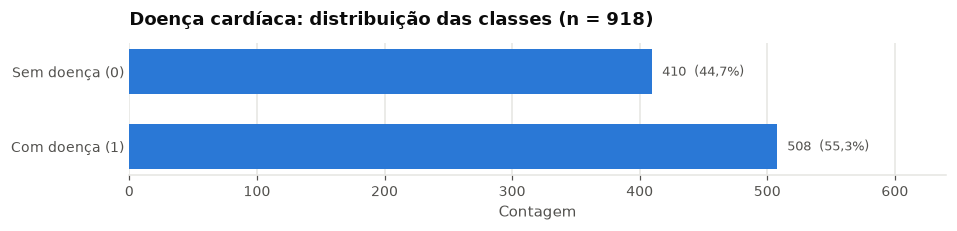

,Contagem,Percentual (%)
Classe,,
Sem doença (0),410,44.66
Com doença (1),508,55.34


In [8]:
tab_alvo = distribuicao_categorica(df, "doenca_cardiaca", ordem=ordem_classes("doenca_cardiaca"))

### 4.2 Sexo (`sexo`)

A amostra é fortemente concentrada no sexo masculino: **725 homens (78,98%)** contra **193 mulheres (21,02%)**, quase 4 homens para cada mulher — reflexo tanto da epidemiologia coronariana na faixa de meia-idade quanto da presença do hospital de veteranos (*Long Beach VA*, que tem 97% de homens).

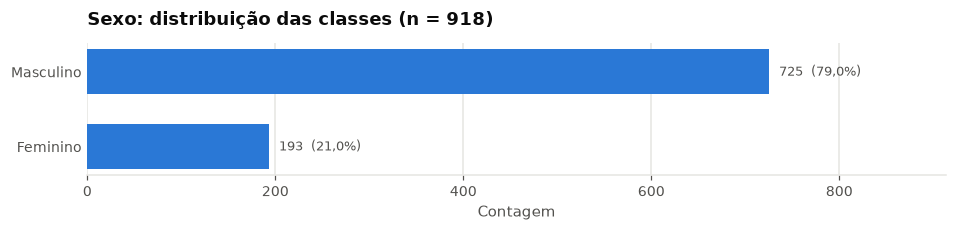

,Contagem,Percentual (%)
Classe,,
Masculino,725,78.98
Feminino,193,21.02


In [9]:
tab_sexo = distribuicao_categorica(df, "sexo", ordem=ordem_classes("sexo"))

### 4.3 Tipo de dor no peito (`tipo_dor_peito`) e Glicemia em jejum (`glicemia_jejum`)

- Mais da metade dos pacientes examinados são **Assintomáticos (`ASY`, 54,03%, 496 casos)** — isto é, não relatam dor anginosa clássica ou apresentam isquemia silenciosa/equivalentes anginosos. **Dor não anginosa (`NAP`, 22,11%)** e **Angina atípica (`ATA`, 18,85%)** vêm em seguida, enquanto a **Angina típica (`TA`)** representa apenas **5,01% (46 casos)**.
- Em relação à **glicemia em jejum**, **76,69% (704)** têm níveis até $120\text{ mg/dL}$ e **23,31% (214)** apresentam hiperglicemia ($> 120\text{ mg/dL}$).

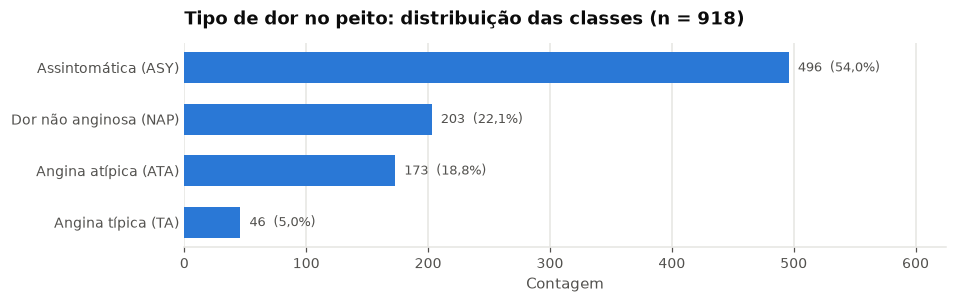

,Contagem,Percentual (%)
Classe,,
Assintomática (ASY),496,54.03
Dor não anginosa (NAP),203,22.11
Angina atípica (ATA),173,18.85
Angina típica (TA),46,5.01


In [10]:
tab_dor = distribuicao_categorica(df, "tipo_dor_peito", ordem=ordem_classes("tipo_dor_peito"))

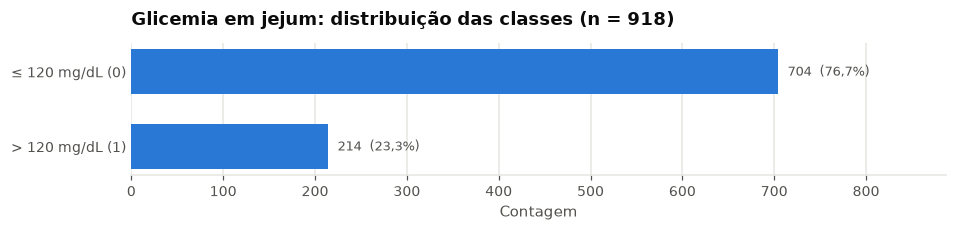

,Contagem,Percentual (%)
Classe,,
≤ 120 mg/dL (0),704,76.69
> 120 mg/dL (1),214,23.31


In [11]:
tab_glicemia = distribuicao_categorica(df, "glicemia_jejum", ordem=ordem_classes("glicemia_jejum"))

### 4.4 Eletrocardiograma em repouso (`ecg_repouso`), Angina no exercício (`angina_exercicio`) e Inclinação de ST (`inclinacao_st`)

- No **ECG em repouso**, **60,13% (552)** têm traçado normal, **20,48% (188)** apresentam critérios de hipertrofia ventricular esquerda (`LVH`) e **19,39% (178)** exibem alterações de onda ST-T (`ST`).
- Durante o teste ergométrico, **40,41% (371)** desenvolvem **angina induzida pelo exercício**.
- Na **inclinação do segmento ST no pico do esforço**, metade da base tem inclinação **Plana (`Flat`, 50,11%, 460)**, **43,03% (395)** têm inclinação fisiológica **Ascendente (`Up`)** e apenas **6,86% (63)** apresentam inclinação **Descendente (`Down`)**.

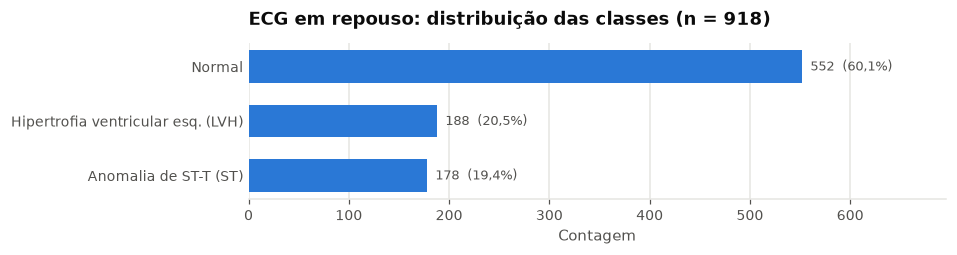

,Contagem,Percentual (%)
Classe,,
Normal,552,60.13
Hipertrofia ventricular esq. (LVH),188,20.48
Anomalia de ST-T (ST),178,19.39


In [12]:
tab_ecg = distribuicao_categorica(df, "ecg_repouso", ordem=ordem_classes("ecg_repouso"))

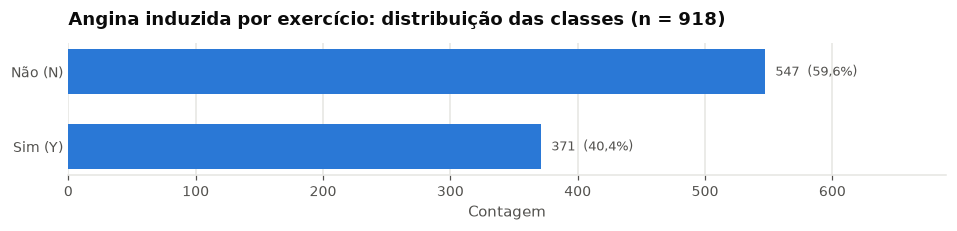

,Contagem,Percentual (%)
Classe,,
Não (N),547,59.59
Sim (Y),371,40.41


In [13]:
tab_angina = distribuicao_categorica(df, "angina_exercicio", ordem=ordem_classes("angina_exercicio"))

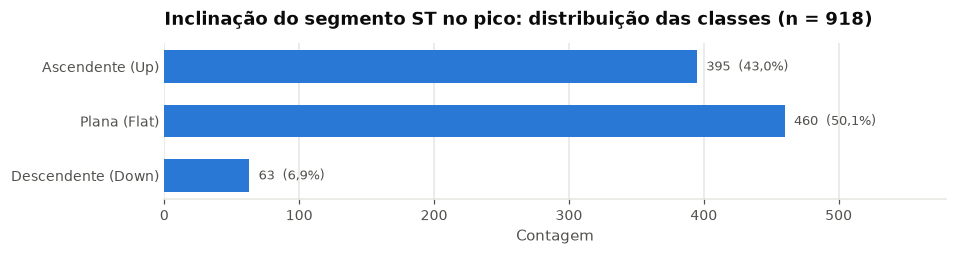

,Contagem,Percentual (%)
Classe,,
Ascendente (Up),395,43.03
Plana (Flat),460,50.11
Descendente (Down),63,6.86


In [14]:
tab_inclinacao = distribuicao_categorica(df, "inclinacao_st", ordem=ordem_classes("inclinacao_st"))

## 5. Análise univariada: atributos numéricos contínuos

Antes de examinar cada variável isoladamente, a tabela abaixo consolida as estatísticas descritivas das 5 variáveis contínuas, comparando `pressao_repouso` e `colesterol` **com** e **sem** os zeros espúrios identificados na Seção 3:

- No `colesterol`, a presença dos 172 zeros derruba artificialmente a média de **$244,64\text{ mg/dL}$ para $198,80\text{ mg/dL}$**, quase dobra o desvio-padrão (de **$59,15$ para $109,38\text{ mg/dL}$**) e inverte a assimetria de **positiva ($+1,24$, cauda longa de hipercolesterolemia)** para **negativa ($-0,61$)**.
- Na `pressao_repouso`, a remoção do único zero (linha 449) reduz a curtose de **$+3,25$ para $+0,78$**.

In [15]:
resumos_num = pd.concat([
    resumo_estatistico_numerico(df["idade"], "Idade (todos, n = 918)"),
    resumo_estatistico_numerico(df["freq_cardiaca_max"], "Frequência cardíaca máx. (todos, n = 918)"),
    resumo_estatistico_numerico(df["pressao_repouso"], "Pressão em repouso (bruta, c/ zero, n = 918)"),
    resumo_estatistico_numerico(df.loc[df["pressao_repouso"] > 0, "pressao_repouso"], "Pressão em repouso (válida > 0, n = 917)"),
    resumo_estatistico_numerico(df["colesterol"], "Colesterol sérico (bruto, c/ 172 zeros, n = 918)"),
    resumo_estatistico_numerico(df.loc[df["colesterol"] > 0, "colesterol"], "Colesterol sérico (válido > 0, n = 746)"),
    resumo_estatistico_numerico(df["depressao_st"], "Depressão de ST / Oldpeak (todos, n = 918)"),
])
display(resumos_num)

,n,média,desvio padrão,mínimo,Q1 (25%),mediana,Q3 (75%),máximo,IQR,assimetria,curtose,outliers IQR
"Idade (todos, n = 918)",918,53.51,9.43,28.0,47.00,54.0,60.0,77.0,13.00,-0.20,-0.39,0
"Frequência cardíaca máx. (todos, n = 918)",918,136.81,25.46,60.0,120.00,138.0,156.0,202.0,36.00,-0.14,-0.45,2
"Pressão em repouso (bruta, c/ zero, n = 918)",918,132.40,18.51,0.0,120.00,130.0,140.0,200.0,20.00,0.18,3.25,28
"Pressão em repouso (válida > 0, n = 917)",917,132.54,18.00,80.0,120.00,130.0,140.0,200.0,20.00,0.61,0.78,27
"Colesterol sérico (bruto, c/ 172 zeros, n = 918)",918,198.80,109.38,0.0,173.25,223.0,267.0,603.0,93.75,-0.61,0.11,183
"Colesterol sérico (válido > 0, n = 746)",746,244.64,59.15,85.0,207.25,237.0,275.0,603.0,67.75,1.24,4.49,23
"Depressão de ST / Oldpeak (todos, n = 918)",918,0.89,1.07,-2.6,0.00,0.6,1.5,6.2,1.50,1.02,1.19,16


### 5.1 Idade (`idade`)

Varia de **28 a 77 anos**, com média de **53,51 anos** e mediana de **54,0 anos** ($\text{Q1} = 47$, $\text{Q3} = 60$). A distribuição é unimodal, levemente assimétrica à esquerda ($\text{assimetria} = -0,20$) e sem nenhum *outlier* pelo critério de Tukey. Cerca de $79\%$ dos pacientes têm entre 45 e 69 anos.

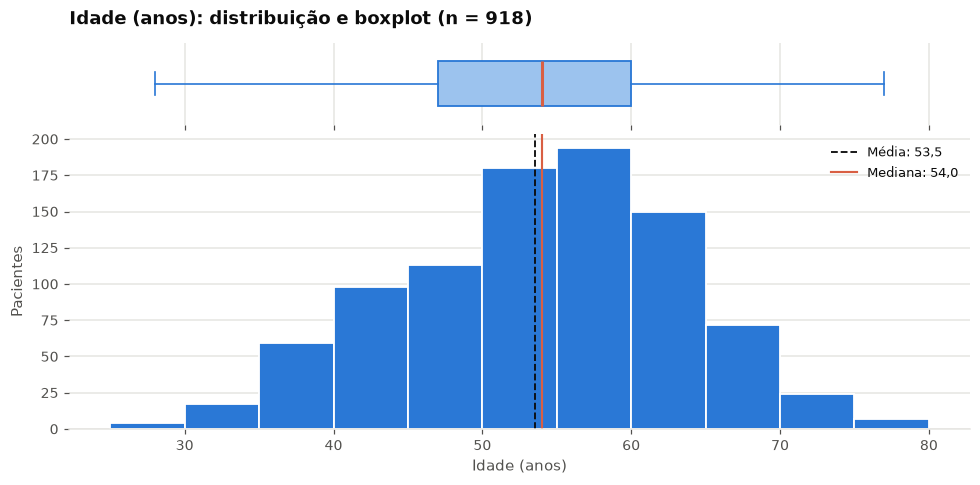

,n,média,desvio padrão,mínimo,Q1 (25%),mediana,Q3 (75%),máximo,IQR,assimetria,curtose,outliers IQR
Idade (anos),918,53.51,9.43,28.0,47.0,54.0,60.0,77.0,13.0,-0.2,-0.39,0


,Contagem,Percentual (%)
Faixa,,
"[25, 30)",4,0.44
"[30, 35)",17,1.85
"[35, 40)",59,6.43
"[40, 45)",98,10.68
"[45, 50)",113,12.31
"[50, 55)",180,19.61
"[55, 60)",194,21.13
"[60, 65)",150,16.34
"[65, 70)",72,7.84


In [16]:
tab_idade_dist = distribuicao_numerica(df, "idade", bins=range(25, 85, 5))

### 5.2 Frequência cardíaca máxima (`freq_cardiaca_max`)

Alcança entre **60 e 202 bpm**, com média de **136,81 bpm** e mediana de **138,0 bpm** ($\text{Q1} = 120$, $\text{Q3} = 156$). A distribuição também é bastante simétrica ($\text{assimetria} = -0,14$), apresentando apenas 2 valores abaixo do limite inferior de Tukey ($60$ e $63\text{ bpm}$).

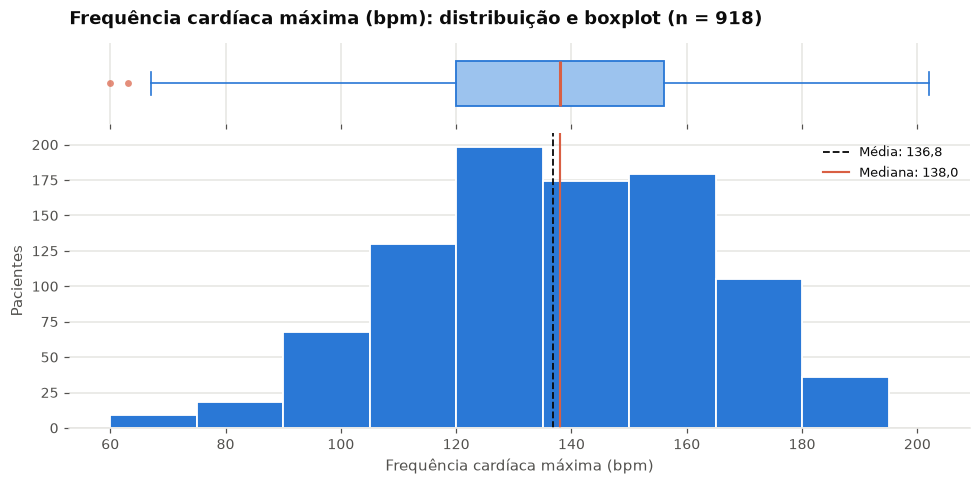

,n,média,desvio padrão,mínimo,Q1 (25%),mediana,Q3 (75%),máximo,IQR,assimetria,curtose,outliers IQR
Frequência cardíaca máxima (bpm),918,136.81,25.46,60.0,120.0,138.0,156.0,202.0,36.0,-0.14,-0.45,2


,Contagem,Percentual (%)
Faixa,,
"[60, 75)",9,0.98
"[75, 90)",18,1.96
"[90, 105)",68,7.42
"[105, 120)",130,14.18
"[120, 135)",198,21.59
"[135, 150)",174,18.97
"[150, 165)",179,19.52
"[165, 180)",105,11.45
"[180, 195]",36,3.93


In [17]:
tab_fc_dist = distribuicao_numerica(df, "freq_cardiaca_max", bins=range(60, 210, 15))

### 5.3 Pressão arterial em repouso (`pressao_repouso`)

Excluindo o único registro igual a zero (linha 449), a pressão sistólica varia de **80 a 200 mmHg**, com média de **132,54 mmHg** e mediana de **130,0 mmHg**. Observam-se dois aspectos importantes para a modelagem:
- **Discretização por arredondamento clínico (*digit preference*):** valores terminados em zero (`120`, `130`, `140`, `150 mmHg`) concentram grande parte das observações, gerando degraus nas faixas `[120, 130)` e `[130, 140)` (que juntas somam $46,9\%$ da base);
- **Cauda superior hipertensiva:** 26 pacientes apresentam valores acima do limite superior de Tukey ($> 170\text{ mmHg}$), chegando a $200\text{ mmHg}$.

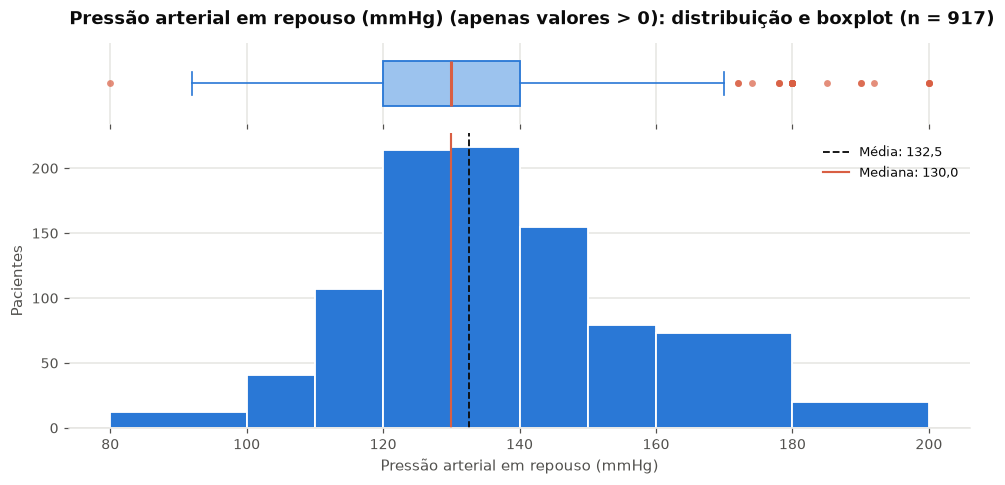

,n,média,desvio padrão,mínimo,Q1 (25%),mediana,Q3 (75%),máximo,IQR,assimetria,curtose,outliers IQR
Pressão arterial em repouso (mmHg) (apenas valores > 0),917,132.54,18.0,80.0,120.0,130.0,140.0,200.0,20.0,0.61,0.78,27


,Contagem,Percentual (%)
Faixa,,
"[80, 100)",12,1.31
"[100, 110)",41,4.47
"[110, 120)",107,11.67
"[120, 130)",214,23.34
"[130, 140)",216,23.56
"[140, 150)",155,16.90
"[150, 160)",79,8.62
"[160, 180)",73,7.96
"[180, 200]",20,2.18


In [18]:
tab_pa_dist = distribuicao_numerica(
    df, "pressao_repouso", bins=[80, 100, 110, 120, 130, 140, 150, 160, 180, 200],
    filtro_positivos=True,
)

### 5.4 Colesterol sérico (`colesterol`)

Primeiro destacamos a proporção de zeros espúrios ($18,74\%$, 172 registros) contra medições válidas ($81,26\%$, 746 registros). Em seguida, avaliamos a distribuição **apenas dos valores positivos ($> 0$):**
- Entre os 746 registros válidos, o colesterol varia de **85 a 603 mg/dL**, com média de **244,64 mg/dL** e mediana de **237,0 mg/dL** ($\text{Q1} = 207,25$, $\text{Q3} = 275,0$);
- A distribuição possui **forte assimetria positiva ($+1,24$) e cauda longa ($\text{curtose} = +4,49$)**, com 14 pacientes em faixa de hipercolesterolemia grave ($> 376,6\text{ mg/dL}$, chegando a $603\text{ mg/dL}$).

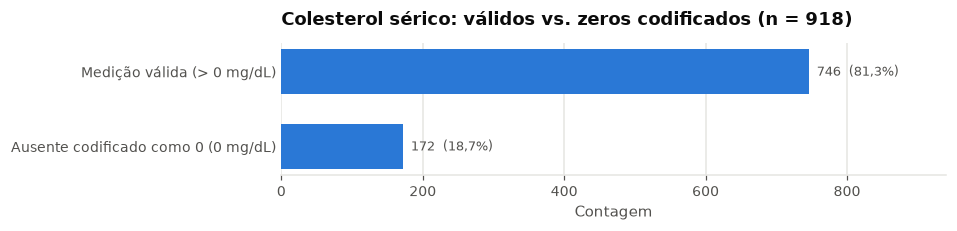

,Contagem,Percentual (%)
Classe,,
Medição válida (> 0 mg/dL),746,81.26
Ausente codificado como 0 (0 mg/dL),172,18.74


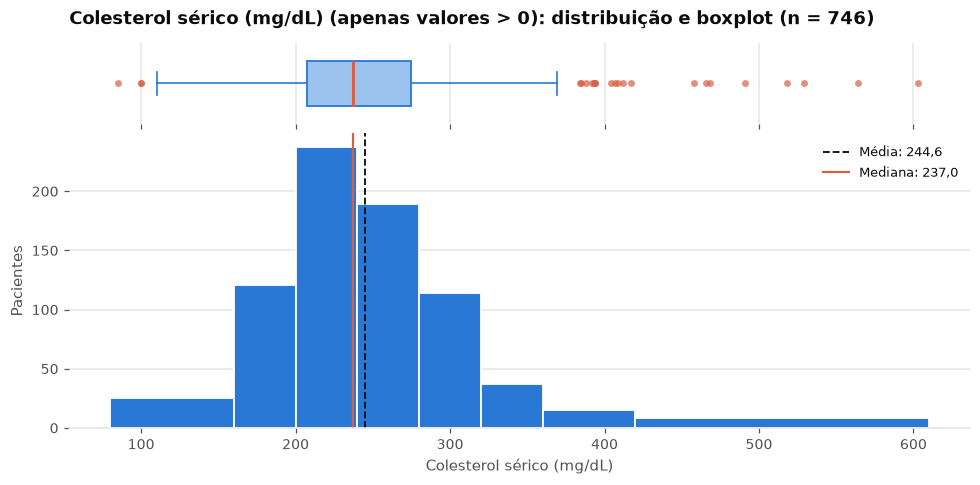

,n,média,desvio padrão,mínimo,Q1 (25%),mediana,Q3 (75%),máximo,IQR,assimetria,curtose,outliers IQR
Colesterol sérico (mg/dL) (apenas valores > 0),746,244.64,59.15,85.0,207.25,237.0,275.0,603.0,67.75,1.24,4.49,23


,Contagem,Percentual (%)
Faixa,,
"[80, 160)",25,3.35
"[160, 200)",121,16.22
"[200, 240)",237,31.77
"[240, 280)",189,25.34
"[280, 320)",114,15.28
"[320, 360)",37,4.96
"[360, 420)",15,2.01
"[420, 610]",8,1.07


In [19]:
status_colesterol = pd.Series(
    np.where(df["colesterol"] > 0, "Medição válida (> 0 mg/dL)", "Ausente codificado como 0 (0 mg/dL)"),
    name="colesterol_status",
)
_ = distribuicao_categorica(
    status_colesterol.to_frame(), "colesterol_status",
    ordem=["Medição válida (> 0 mg/dL)", "Ausente codificado como 0 (0 mg/dL)"],
    titulo=f"Colesterol sérico: válidos vs. zeros codificados (n = {formatar_int(len(df))})",
)

tab_col_dist = distribuicao_numerica(
    df, "colesterol", bins=[80, 160, 200, 240, 280, 320, 360, 420, 610],
    filtro_positivos=True,
)

### 5.5 Depressão do segmento ST (`depressao_st` / *Oldpeak*)

A variável `depressao_st` apresenta uma distribuição **semicontínua (inflada em zero)** e fortemente assimétrica à direita ($\text{assimetria} = +1,02$):
- **40,09% (368 pacientes)** têm valor exatamente igual a **$0,0\text{ mV}$** (sem desnivelamento do segmento ST no esforço);
- **1,42% (13 pacientes)** têm valores **negativos** ($-2,6$ a $-0,1\text{ mV}$, elevação de ST);
- **58,50% (537 pacientes)** têm depressão **positiva** ($0,1$ a $6,2\text{ mV}$), com 16 *outliers* pelo critério de Tukey.

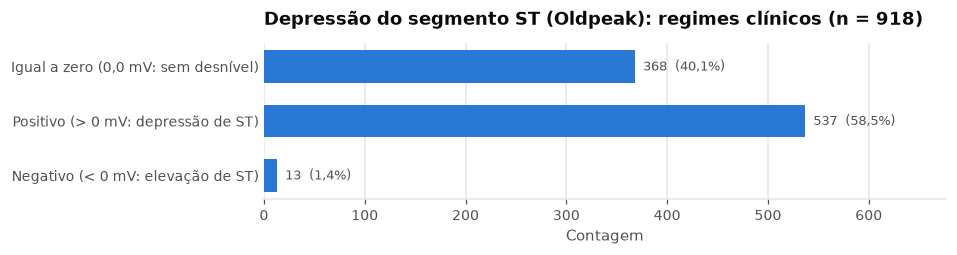

,Contagem,Percentual (%)
Classe,,
"Igual a zero (0,0 mV: sem desnível)",368,40.09
Positivo (> 0 mV: depressão de ST),537,58.50
Negativo (< 0 mV: elevação de ST),13,1.42


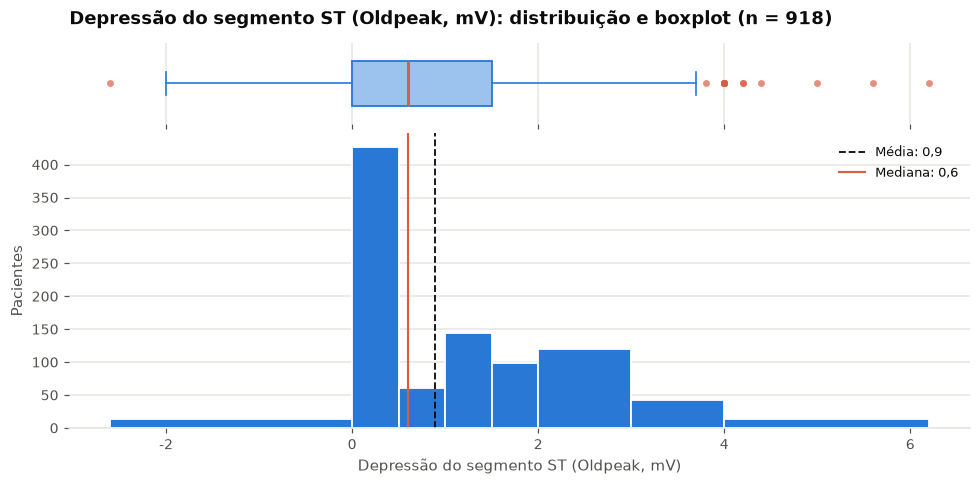

,n,média,desvio padrão,mínimo,Q1 (25%),mediana,Q3 (75%),máximo,IQR,assimetria,curtose,outliers IQR
"Depressão do segmento ST (Oldpeak, mV)",918,0.89,1.07,-2.6,0.0,0.6,1.5,6.2,1.5,1.02,1.19,16


,Contagem,Percentual (%)
Faixa,,
"[-2,6, 0,0)",13,1.42
"[0,0, 0,5)",426,46.41
"[0,5, 1,0)",60,6.54
"[1,0, 1,5)",144,15.69
"[1,5, 2,0)",99,10.78
"[2,0, 3,0)",120,13.07
"[3,0, 4,0)",42,4.58
"[4,0, 6,2]",14,1.53


In [20]:
regime_st = pd.Series(
    np.where(df["depressao_st"] < 0, "Negativo (< 0 mV: elevação de ST)",
             np.where(df["depressao_st"] == 0, "Igual a zero (0,0 mV: sem desnível)", "Positivo (> 0 mV: depressão de ST)")),
    name="regime_st",
)
_ = distribuicao_categorica(
    regime_st.to_frame(), "regime_st",
    ordem=["Igual a zero (0,0 mV: sem desnível)", "Positivo (> 0 mV: depressão de ST)", "Negativo (< 0 mV: elevação de ST)"],
    titulo=f"Depressão do segmento ST (Oldpeak): regimes clínicos (n = {formatar_int(len(df))})",
)

tab_st_dist = distribuicao_numerica(
    df, "depressao_st", bins=[-2.6, 0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.2], casas_faixa=1
)

## 6. Análise bivariada: atributos categóricos × doença cardíaca

Para quantificar objetivamente a força de associação de cada atributo categórico (e do estado de ausência do colesterol) com o diagnóstico de doença cardíaca, calculamos a estatística **$\chi^2$ de independência de Pearson** e o coeficiente **$V$ de Cramér** ($V \in [0, 1]$, onde valores acima de $0,30$ indicam associação forte e acima de $0,50$ associação muito forte):

$$V = \sqrt{\frac{\chi^2}{n \cdot \min(r - 1, c - 1)}}$$

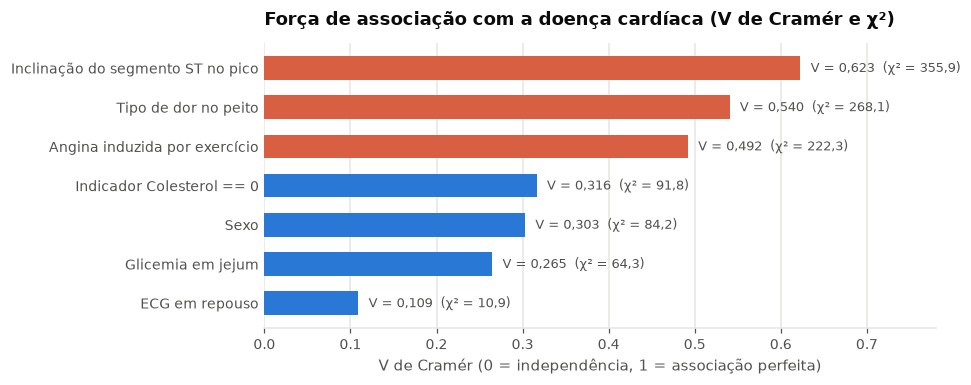

,Classes (k),Graus de liberdade,Qui-quadrado (χ²),V de Cramér,p-valor
Atributo,,,,,
Inclinação do segmento ST no pico,3,2,355.92,0.6227,5.17e-78
Tipo de dor no peito,4,3,268.07,0.5404,8.08e-58
Angina induzida por exercício,2,1,222.26,0.4920,2.91e-50
Indicador Colesterol == 0,2,1,91.82,0.3163,9.50e-22
Sexo,2,1,84.15,0.3028,4.60e-20
Glicemia em jejum,2,1,64.32,0.2647,1.06e-15
ECG em repouso,3,2,10.93,0.1091,4.23e-03


In [21]:
cat_analise = [
    ("inclinacao_st", df["inclinacao_st"]),
    ("tipo_dor_peito", df["tipo_dor_peito"]),
    ("angina_exercicio", df["angina_exercicio"]),
    ("colesterol_zero (indicador)", pd.Series(np.where(df["colesterol"] == 0, "Zero (ausente)", "Válido (> 0)"))),
    ("sexo", df["sexo"]),
    ("glicemia_jejum", df["glicemia_jejum"]),
    ("ecg_repouso", df["ecg_repouso"]),
]

linhas_chi = []
for nome_col, serie in cat_analise:
    ct = pd.crosstab(serie, df["doenca_cardiaca"])
    chi2, p_val, dof, _ = stats.chi2_contingency(ct)
    v_cramer = np.sqrt(chi2 / (len(df) * (min(ct.shape) - 1)))
    linhas_chi.append({
        "Atributo": rotulo(nome_col) if nome_col in df.columns else "Indicador Colesterol == 0",
        "Classes (k)": ct.shape[0],
        "Graus de liberdade": dof,
        "Qui-quadrado (χ²)": round(chi2, 2),
        "V de Cramér": round(v_cramer, 4),
        "p-valor": f"{p_val:.2e}",
    })

tab_cramer = pd.DataFrame(linhas_chi).sort_values("V de Cramér", ascending=False).set_index("Atributo")

fig, ax = plt.subplots(figsize=(8.8, 3.6))
pos = np.arange(len(tab_cramer))[::-1]
vals_v = tab_cramer["V de Cramér"].values
cores_v = [CORAL if v >= 0.45 else AZUL for v in vals_v]
ax.barh(pos, vals_v, color=cores_v, height=0.6)
ax.set_yticks(pos, list(tab_cramer.index))
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
for p_i, v_i, chi_i in zip(pos, vals_v, tab_cramer["Qui-quadrado (χ²)"].values):
    ax.text(v_i + 0.012, p_i, f"V = {formatar_num(v_i, 3)}  (χ² = {formatar_num(chi_i, 1)})",
            va="center", fontsize=8.5, color=TEXTO_SEC)
ax.set_xlim(0, 0.78)
ax.set_title("Força de associação com a doença cardíaca (V de Cramér e χ²)")
ax.set_xlabel("V de Cramér (0 = independência, 1 = associação perfeita)")
plt.tight_layout()
plt.show()

display(tab_cramer)

### 6.1 Inclinação do segmento ST (`inclinacao_st`) — $V = 0,623$

É o **atributo isolado mais discriminante de todo o conjunto de dados**:
- Quando a inclinação do segmento ST no pico do esforço é **Plana (`Flat`)**, **82,83% (381 de 460)** dos pacientes têm doença cardíaca;
- Quando é **Descendente (`Down`)**, **77,78% (49 de 63)** têm doença cardíaca;
- Em contrapartida, quando a inclinação é **Ascendente (`Up`)** (resposta fisiológica normal à taquicardia do esforço), a prevalência despenca para **19,75% (78 de 395)**.

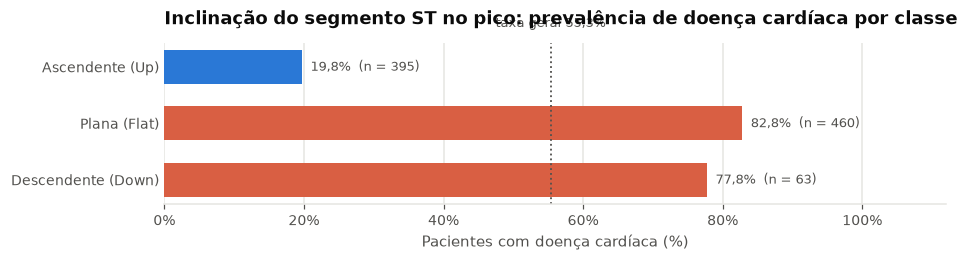

,Total,Sem doença (0),Com doença (1),Taxa de doença (%)
Inclinação do segmento ST no pico,,,,
Ascendente (Up),395,317,78,19.75
Plana (Flat),460,79,381,82.83
Descendente (Down),63,14,49,77.78


In [22]:
_ = taxa_por_categoria(df, "inclinacao_st", ordem=ordem_classes("inclinacao_st"))

### 6.2 Tipo de dor no peito (`tipo_dor_peito`) — $V = 0,540$

O segundo preditor mais forte revela um padrão fundamental das coortes angiográficas do UCI:
- Pacientes classificados como **Assintomáticos (`ASY`)** têm **79,03% de prevalência de doença cardíaca (392 de 496)** — sozinhos, eles respondem por **$77,17\%$ de todos os 508 casos positivos da base**!
- Pacientes com **Angina típica (`TA`)** têm taxa de **43,48%**, **Dor não anginosa (`NAP`)** **35,47%** e **Angina atípica (`ATA`)** apenas **13,87% (24 de 173)**.

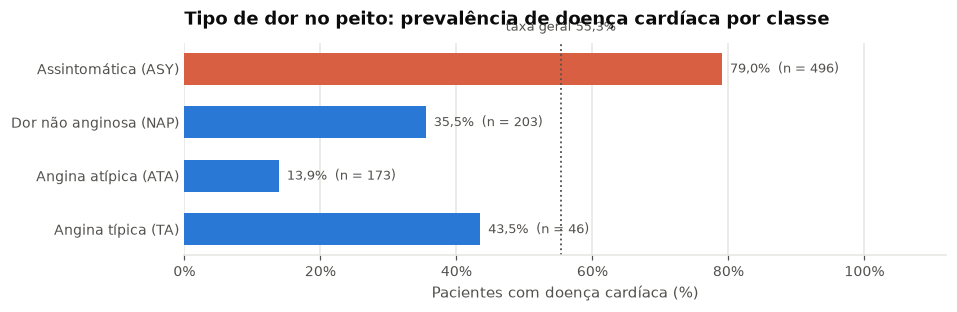

,Total,Sem doença (0),Com doença (1),Taxa de doença (%)
Tipo de dor no peito,,,,
Assintomática (ASY),496,104,392,79.03
Dor não anginosa (NAP),203,131,72,35.47
Angina atípica (ATA),173,149,24,13.87
Angina típica (TA),46,26,20,43.48


In [23]:
_ = taxa_por_categoria(df, "tipo_dor_peito", ordem=ordem_classes("tipo_dor_peito"))

### 6.3 Angina induzida por exercício (`angina_exercicio`) — $V = 0,492$

A ocorrência de angina durante o teste ergométrico separa fortemente os dois grupos: **85,18% (316 de 371)** dos pacientes com angina no esforço (`Sim`) possuem doença coronariana, contra **35,10% (192 de 547)** dos que não desenvolvem dor (`Não`).

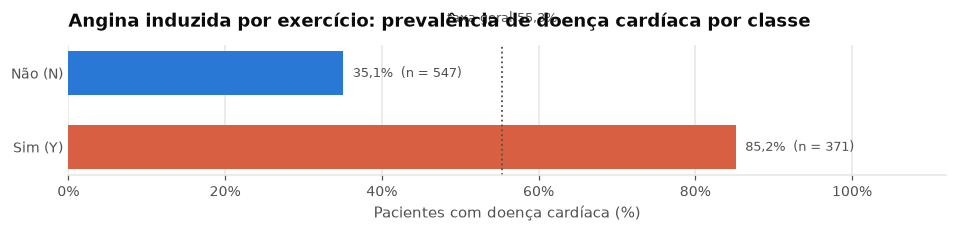

,Total,Sem doença (0),Com doença (1),Taxa de doença (%)
Angina induzida por exercício,,,,
Não (N),547,355,192,35.10
Sim (Y),371,55,316,85.18


In [24]:
_ = taxa_por_categoria(df, "angina_exercicio", ordem=ordem_classes("angina_exercicio"))

### 6.4 Sexo (`sexo`) e Glicemia em jejum (`glicemia_jejum`) — $V = 0,303$ e $V = 0,265$

- **Sexo:** homens apresentam prevalência de **63,17% (458 de 725)**, mais que o dobro da observada nas mulheres (**25,91%, 50 de 193**).
- **Glicemia em jejum:** pacientes com glicemia $> 120\text{ mg/dL}$ têm **79,44% (170 de 214)** de taxa de doença, contra **48,01% (338 de 704)** nos normoglicêmicos.

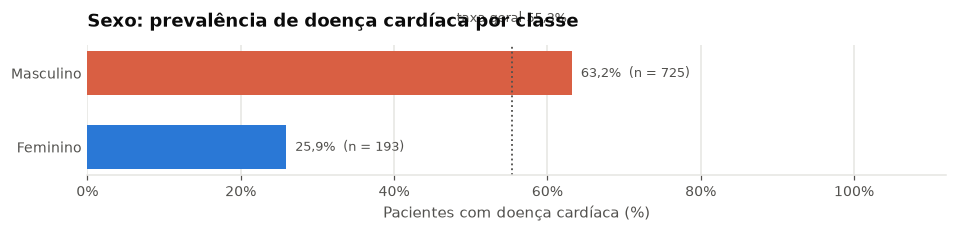

,Total,Sem doença (0),Com doença (1),Taxa de doença (%)
Sexo,,,,
Masculino,725,267,458,63.17
Feminino,193,143,50,25.91


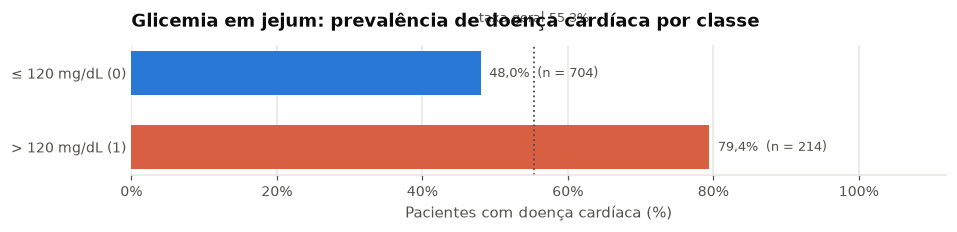

,Total,Sem doença (0),Com doença (1),Taxa de doença (%)
Glicemia em jejum,,,,
≤ 120 mg/dL (0),704,366,338,48.01
> 120 mg/dL (1),214,44,170,79.44


In [25]:
_ = taxa_por_categoria(df, "sexo", ordem=ordem_classes("sexo"))
_ = taxa_por_categoria(df, "glicemia_jejum", ordem=ordem_classes("glicemia_jejum"))

### 6.5 Eletrocardiograma em repouso (`ecg_repouso`) — $V = 0,109$

É o atributo categórico de menor poder discriminativo isolado, embora ainda estatisticamente significativo ($p = 0,0042$): pacientes com **Anomalia de ST-T (`ST`)** apresentam **65,73%** de doença, seguidos por **Hipertrofia ventricular esquerda (`LVH`, 56,38%)** e **ECG Normal (`51,63%`)**.

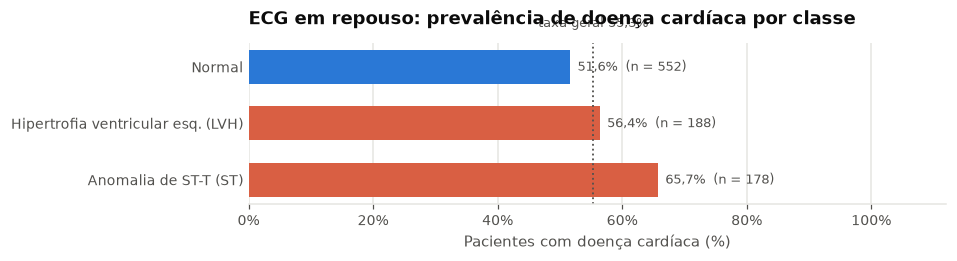

,Total,Sem doença (0),Com doença (1),Taxa de doença (%)
ECG em repouso,,,,
Normal,552,267,285,51.63
Hipertrofia ventricular esq. (LVH),188,82,106,56.38
Anomalia de ST-T (ST),178,61,117,65.73


In [26]:
_ = taxa_por_categoria(df, "ecg_repouso", ordem=ordem_classes("ecg_repouso"))

## 7. Análise bivariada: atributos numéricos × doença cardíaca

Para avaliar a relação das variáveis numéricas com a variável-alvo binária (`0` vs. `1`), calculamos três medidas complementares:
1. **Correlação ponto-bisserial ($r_{pb}$, equivalente ao $r$ de Pearson):** sensível a relações lineares e a *outliers*/zeros espúrios;
2. **Correlação de postos de Spearman ($\rho$):** mede associação monotônica, robusta a caudas pesadas;
3. **Teste não paramétrico de Mann-Whitney $U$:** testa se a distribuição nos pacientes com doença é estocasticamente diferente da distribuição nos pacientes sem doença.

In [27]:
y_bin = (df["doenca_cardiaca"] == "Com doença (1)").astype(int).values

avaliacoes_num = [
    ("Depressão de ST (Oldpeak) — todos (n = 918)", df["depressao_st"].values, y_bin),
    ("Frequência cardíaca máx. — todos (n = 918)", df["freq_cardiaca_max"].values, y_bin),
    ("Idade — todos (n = 918)", df["idade"].values, y_bin),
    ("Pressão em repouso — válida (> 0, n = 917)", df.loc[df["pressao_repouso"] > 0, "pressao_repouso"].values, y_bin[df["pressao_repouso"] > 0]),
    ("Pressão em repouso — bruta (c/ zero, n = 918)", df["pressao_repouso"].values, y_bin),
    ("Colesterol sérico — válido (> 0, n = 746)", df.loc[df["colesterol"] > 0, "colesterol"].values, y_bin[df["colesterol"] > 0]),
    ("Colesterol sérico — bruto (c/ 172 zeros, n = 918)", df["colesterol"].values, y_bin),
]

linhas_testes = []
for rot, x_arr, y_arr in avaliacoes_num:
    r_pb, p_pb = stats.pointbiserialr(y_arr, x_arr)
    rho, p_rho = stats.spearmanr(y_arr, x_arr)
    u_stat, p_mw = stats.mannwhitneyu(x_arr[y_arr == 1], x_arr[y_arr == 0])
    linhas_testes.append({
        "Variável / recorte": rot,
        "Média (Sem doença)": round(float(x_arr[y_arr == 0].mean()), 2),
        "Média (Com doença)": round(float(x_arr[y_arr == 1].mean()), 2),
        "Mediana (Sem doença)": round(float(np.median(x_arr[y_arr == 0])), 2),
        "Mediana (Com doença)": round(float(np.median(x_arr[y_arr == 1])), 2),
        "r ponto-bisserial": round(float(r_pb), 4),
        "ρ de Spearman": round(float(rho), 4),
        "p-valor (Mann-Whitney)": f"{p_mw:.2e}",
    })

tab_testes_num = pd.DataFrame(linhas_testes).set_index("Variável / recorte")
display(tab_testes_num)

,Média (Sem doença),Média (Com doença),Mediana (Sem doença),Mediana (Com doença),r ponto-bisserial,ρ de Spearman,p-valor (Mann-Whitney)
Variável / recorte,,,,,,,
Depressão de ST (Oldpeak) — todos (n = 918),0.41,1.27,0.0,1.2,0.4040,0.4190,6.77e-37
Frequência cardíaca máx. — todos (n = 918),148.15,127.66,150.0,126.0,-0.4004,-0.4048,1.51e-34
Idade — todos (n = 918),50.55,55.90,51.0,57.0,0.2820,0.2896,1.81e-18
"Pressão em repouso — válida (> 0, n = 917)",130.18,134.45,130.0,132.0,0.1180,0.1158,4.57e-04
"Pressão em repouso — bruta (c/ zero, n = 918)",130.18,134.19,130.0,132.0,0.1076,0.1139,5.65e-04
"Colesterol sérico — válido (> 0, n = 746)",238.77,251.06,231.5,246.0,0.1039,0.1149,1.71e-03
"Colesterol sérico — bruto (c/ 172 zeros, n = 918)",227.12,175.94,227.0,217.0,-0.2327,-0.1399,2.28e-05


### 7.1 Depressão do segmento ST (`depressao_st` / *Oldpeak*) — $r_{pb} = +0,404$, $\rho = +0,419$

É a variável contínua de maior poder preditivo:
- A média nos pacientes com doença é mais de **três vezes superior** à dos sem doença (**$1,27\text{ mV}$ vs. $0,41\text{ mV}$**; mediana de **$1,20\text{ mV}$ vs. $0,00\text{ mV}$**);
- O gráfico por faixa revela uma **forte não linearidade em três regimes**:
  1. Pacientes com `depressao_st < 0` (elevação de ST, $n = 13$) têm **69,23%** de prevalência de doença;
  2. Pacientes sem desnivelamento (`[0,0, 0,1)`, ou seja, `Oldpeak == 0`, $n = 368$) têm a menor taxa (**33,70%**);
  3. A partir de $1,0\text{ mV}$, o risco dispara para **72,43%** em `[1,0, 2,0)`, **85,00%** em `[2,0, 3,0)` e **91,07%** em `[3,0, 6,5]`.

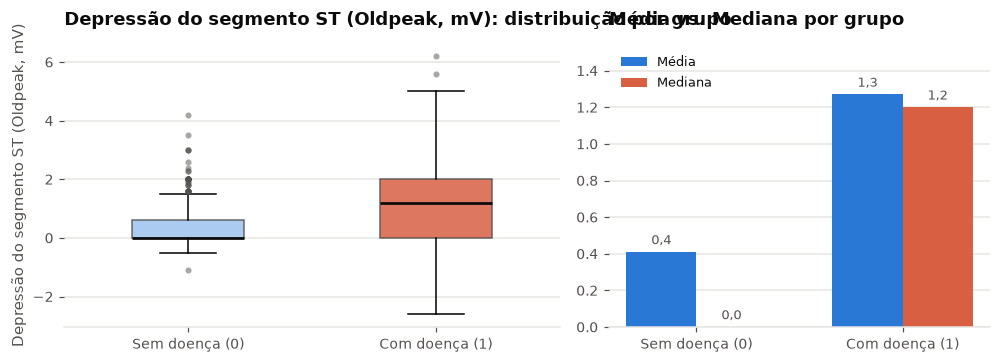

,n,Média,DP,Mínimo,Q1,Mediana,Q3,Máximo
Doença cardíaca,,,,,,,,
Sem doença (0),410,0.41,0.70,-1.1,0.0,0.0,0.6,4.2
Com doença (1),508,1.27,1.15,-2.6,0.0,1.2,2.0,6.2


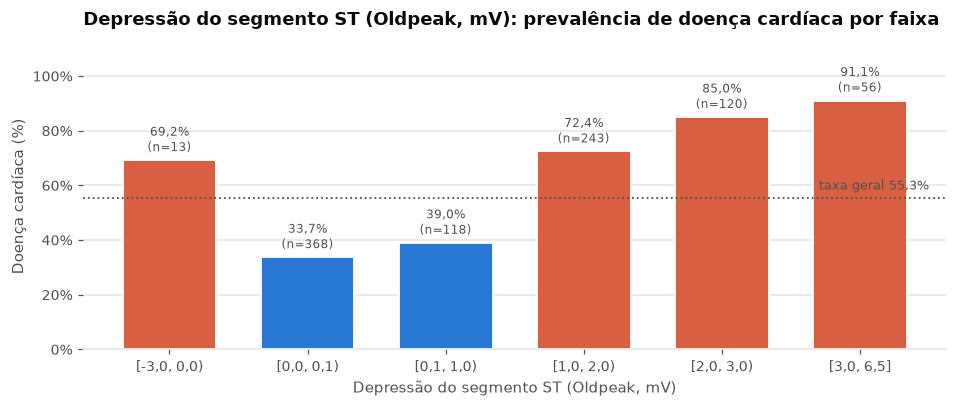

,Total,Sem doença (0),Com doença (1),Taxa de doença (%)
Faixa,,,,
"[-3,0, 0,0)",13,4,9,69.23
"[0,0, 0,1)",368,244,124,33.70
"[0,1, 1,0)",118,72,46,38.98
"[1,0, 2,0)",243,67,176,72.43
"[2,0, 3,0)",120,18,102,85.00
"[3,0, 6,5]",56,5,51,91.07


In [28]:
_ = comparar_grupos_numerico(df, "depressao_st")
_ = taxa_por_faixa(df, "depressao_st", bins=[-3.0, 0.0, 0.1, 1.0, 2.0, 3.0, 6.5], casas_faixa=1)

### 7.2 Frequência cardíaca máxima (`freq_cardiaca_max`) — $r_{pb} = -0,400$, $\rho = -0,405$

Apresenta relação inversa forte e monotônica com a doença cardíaca (incompetência cronotrópica / limitação funcional pela isquemia):
- Pacientes sem doença alcançam em média **148,15 bpm** (mediana **150,0 bpm**), enquanto pacientes com doença atingem **127,66 bpm** (mediana **126,0 bpm**), uma diferença de mais de $20\text{ bpm}$;
- A prevalência de doença cai de forma contínua a cada faixa: de **83,10%** entre `[60, 100) bpm` e **76,62%** em `[100, 120) bpm` para apenas **26,22%** em `[160, 180) bpm` e **16,22%** acima de `180 bpm`.

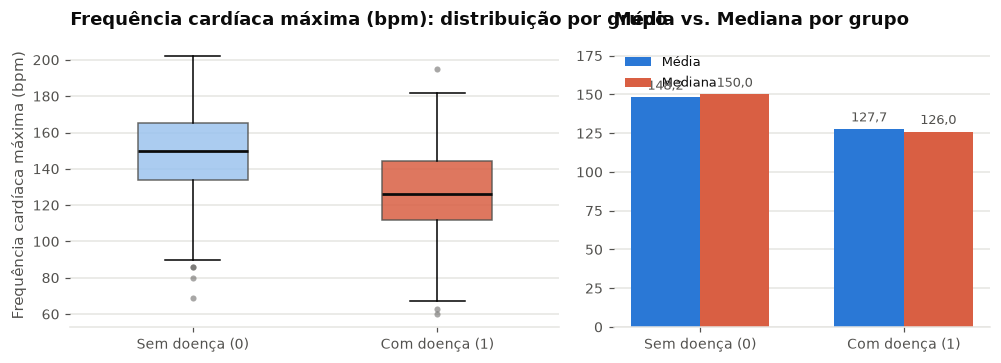

,n,Média,DP,Mínimo,Q1,Mediana,Q3,Máximo
Doença cardíaca,,,,,,,,
Sem doença (0),410,148.15,23.29,69,134.0,150.0,165.00,202
Com doença (1),508,127.66,23.39,60,112.0,126.0,144.25,195


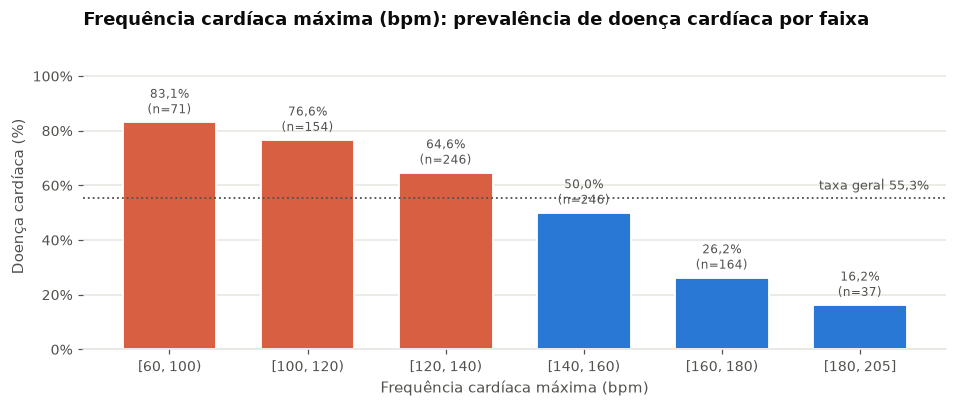

,Total,Sem doença (0),Com doença (1),Taxa de doença (%)
Faixa,,,,
"[60, 100)",71,12,59,83.10
"[100, 120)",154,36,118,76.62
"[120, 140)",246,87,159,64.63
"[140, 160)",246,123,123,50.00
"[160, 180)",164,121,43,26.22
"[180, 205]",37,31,6,16.22


In [29]:
_ = comparar_grupos_numerico(df, "freq_cardiaca_max")
_ = taxa_por_faixa(df, "freq_cardiaca_max", bins=[60, 100, 120, 140, 160, 180, 205])

### 7.3 Idade (`idade`) — $r_{pb} = +0,282$, $\rho = +0,290$

Pacientes com doença cardíaca são, em média, **5,35 anos mais velhos** (**55,90 vs. 50,55 anos**; medianas de **57,0 vs. 51,0 anos**). A prevalência de doença parte de **28,57%** abaixo dos 35 anos, permanece em torno de **47%** entre 45 e 54 anos e salta para **64,95%** na faixa `[55, 60)` e **75,33%** em `[60, 65)`.

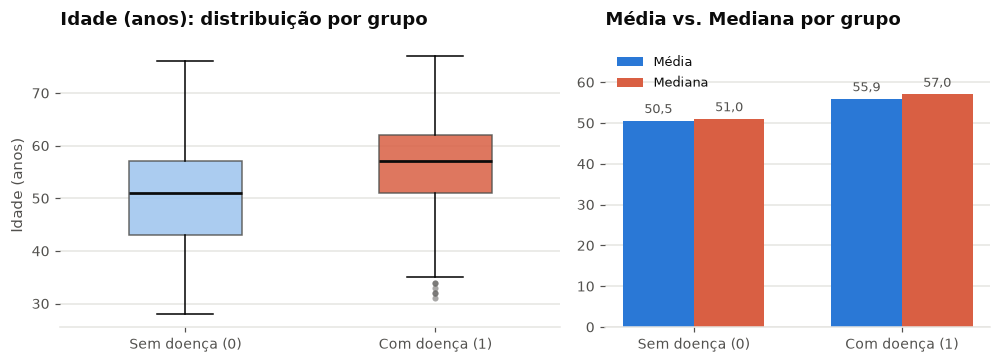

,n,Média,DP,Mínimo,Q1,Mediana,Q3,Máximo
Doença cardíaca,,,,,,,,
Sem doença (0),410,50.55,9.44,28,43.0,51.0,57.0,76
Com doença (1),508,55.90,8.73,31,51.0,57.0,62.0,77


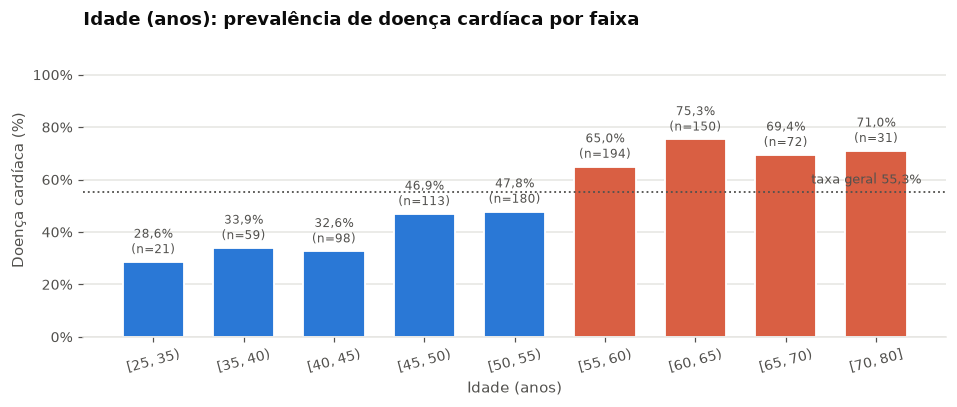

,Total,Sem doença (0),Com doença (1),Taxa de doença (%)
Faixa,,,,
"[25, 35)",21,15,6,28.57
"[35, 40)",59,39,20,33.90
"[40, 45)",98,66,32,32.65
"[45, 50)",113,60,53,46.90
"[50, 55)",180,94,86,47.78
"[55, 60)",194,68,126,64.95
"[60, 65)",150,37,113,75.33
"[65, 70)",72,22,50,69.44
"[70, 80]",31,9,22,70.97


In [30]:
_ = comparar_grupos_numerico(df, "idade")
_ = taxa_por_faixa(df, "idade", bins=[25, 35, 40, 45, 50, 55, 60, 65, 70, 80])

### 7.4 Pressão arterial em repouso (`pressao_repouso > 0`) — $r_{pb} = +0,118$, $\rho = +0,116$

A diferença de médias entre os grupos é modesta (**134,45 vs. 130,18 mmHg**, medianas **132,0 vs. 130,0 mmHg**, $p = 0,00046$). Contudo, a análise por faixas mostra que pacientes com hipertensão estágio 1 (`[140, 160) mmHg`) já superam a média da base (**60,65% a 58,23%**), e na hipertensão estágio 2 (`[160, 200] mmHg`, $n = 93$) a taxa de doença atinge **69,89%**.

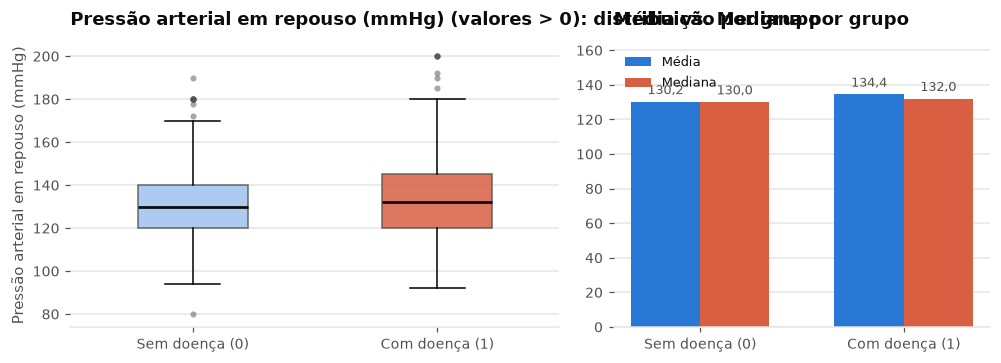

,n,Média,DP,Mínimo,Q1,Mediana,Q3,Máximo
Doença cardíaca,,,,,,,,
Sem doença (0),410,130.18,16.50,80,120.0,130.0,140.0,190
Com doença (1),507,134.45,18.93,92,120.0,132.0,145.0,200


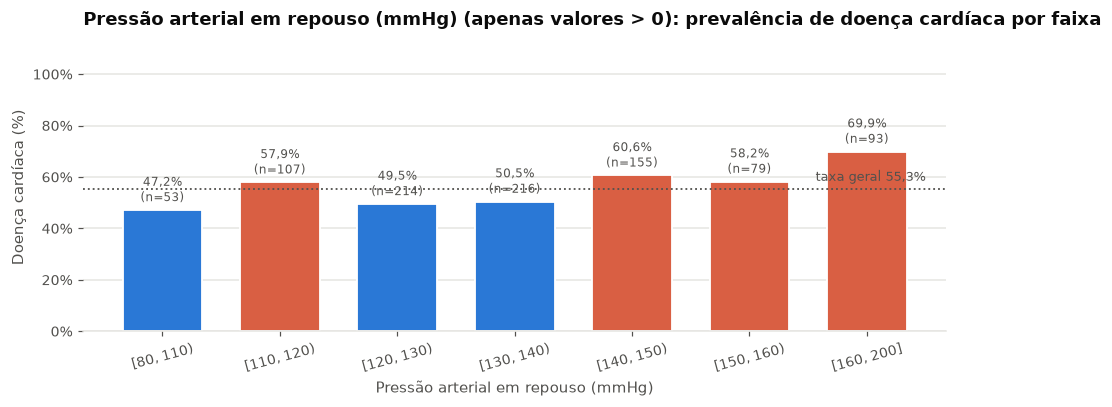

,Total,Sem doença (0),Com doença (1),Taxa de doença (%)
Faixa,,,,
"[80, 110)",53,28,25,47.17
"[110, 120)",107,45,62,57.94
"[120, 130)",214,108,106,49.53
"[130, 140)",216,107,109,50.46
"[140, 150)",155,61,94,60.65
"[150, 160)",79,33,46,58.23
"[160, 200]",93,28,65,69.89


In [31]:
_ = comparar_grupos_numerico(df, "pressao_repouso", filtro_positivos=True)
_ = taxa_por_faixa(df, "pressao_repouso", bins=[80, 110, 120, 130, 140, 150, 160, 200], filtro_positivos=True)

### 7.5 O Paradoxo de Simpson no Colesterol Sérico (`colesterol`)

O colesterol sérico protagoniza a armadilha estatística mais importante desta base:

- **Na base bruta ($n = 918$):** a correlação com a doença cardíaca é **negativa ($r_{pb} = -0,2327$, $\rho = -0,1399$)**! A média bruta do grupo com doença é de **$175,94\text{ mg/dL}$** (com $\text{Q1} = 0,0$), menor que a do grupo sem doença (**$227,12\text{ mg/dL}$**). Um modelo linear ou uma rede neural treinada diretamente sobre a coluna bruta aprenderá um peso **negativo** para o colesterol (interpretando que quanto menor o colesterol, maior o risco de infarto), apenas porque 152 dos 172 zeros pertencem a pacientes cardiopatas das coortes da Suíça e de Long Beach VA.
- **Nas medições fisiológicas válidas (`colesterol > 0`, $n = 746$):** o sinal **inverte completamente para positivo ($r_{pb} = +0,1039$, $\rho = +0,1149$, Mann-Whitney $p = 0,0017$)**! Pacientes com doença têm média de **$251,06\text{ mg/dL}$** e mediana de **$246,00\text{ mg/dL}$**, contra média de **$238,77\text{ mg/dL}$** e mediana de **$231,50\text{ mg/dL}$** nos pacientes sem doença.
- **Comportamento por faixa (`colesterol > 0`):** a taxa de doença atinge o mínimo na faixa desejável `[160, 200) mg/dL` (**36,36%**) e sobe progressivamente até **57,89%** em `[280, 320)` e **58,33%** em `[320, 610] mg/dL` (notando-se também uma pequena cauda à esquerda em `[80, 160)`, com $n = 25$ e taxa de $52,00\%$).

=== A) Colesterol BRUTO (incluindo os 172 zeros espúrios, n = 918) — Distorção por Paradoxo de Simpson ===
=== B) Colesterol VÁLIDO (apenas medições > 0 mg/dL, n = 746) — Relação fisiológica real ===


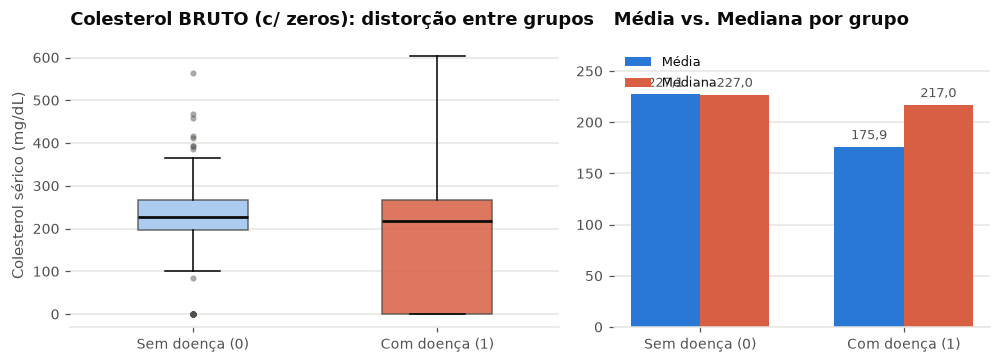

,n,Média,DP,Mínimo,Q1,Mediana,Q3,Máximo
Doença cardíaca,,,,,,,,
Sem doença (0),410,227.12,74.63,0,197.25,227.0,266.75,564
Com doença (1),508,175.94,126.39,0,0.00,217.0,267.00,603


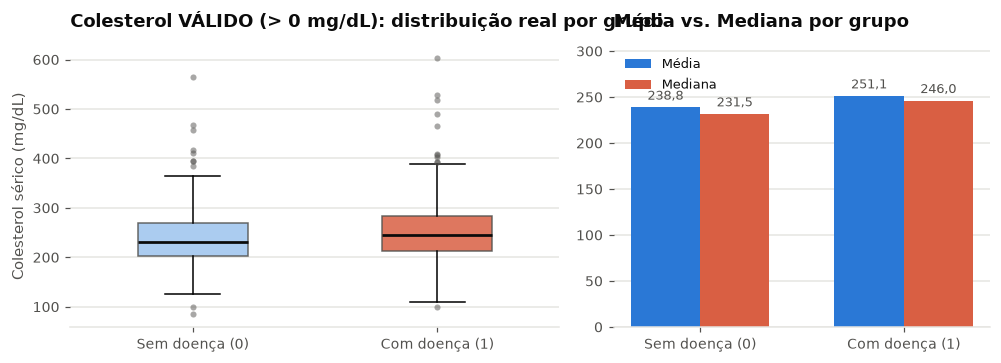

,n,Média,DP,Mínimo,Q1,Mediana,Q3,Máximo
Doença cardíaca,,,,,,,,
Sem doença (0),390,238.77,55.39,85,203.0,231.5,269.00,564
Com doença (1),356,251.06,62.46,100,212.0,246.0,283.25,603


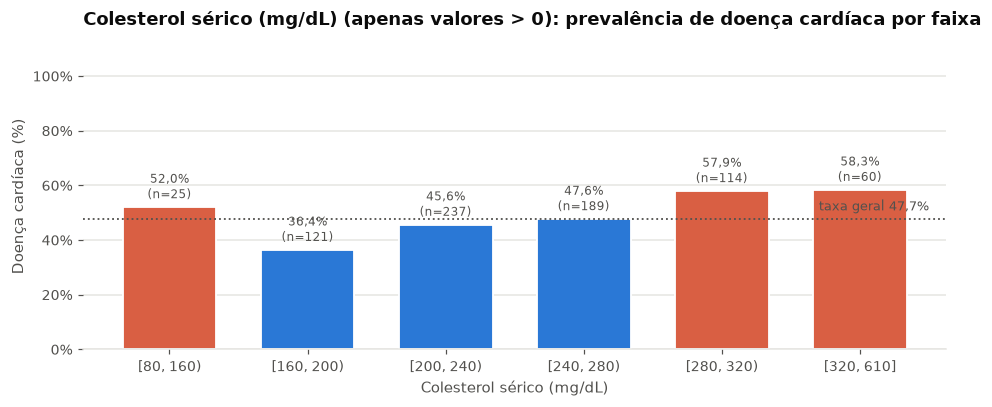

,Total,Sem doença (0),Com doença (1),Taxa de doença (%)
Faixa,,,,
"[80, 160)",25,12,13,52.00
"[160, 200)",121,77,44,36.36
"[200, 240)",237,129,108,45.57
"[240, 280)",189,99,90,47.62
"[280, 320)",114,48,66,57.89
"[320, 610]",60,25,35,58.33


In [32]:
print("=== A) Colesterol BRUTO (incluindo os 172 zeros espúrios, n = 918) — Distorção por Paradoxo de Simpson ===")
_ = comparar_grupos_numerico(df, "colesterol", filtro_positivos=False, titulo="Colesterol BRUTO (c/ zeros): distorção entre grupos")

print("=== B) Colesterol VÁLIDO (apenas medições > 0 mg/dL, n = 746) — Relação fisiológica real ===")
_ = comparar_grupos_numerico(df, "colesterol", filtro_positivos=True, titulo="Colesterol VÁLIDO (> 0 mg/dL): distribuição real por grupo")
_ = taxa_por_faixa(df, "colesterol", bins=[80, 160, 200, 240, 280, 320, 610], filtro_positivos=True)

## 8. Análise multivariada, correlações e interações

### 8.1 Matriz de correlação: base bruta vs. base sem zeros espúrios

Para visualizar o impacto global do tratamento de `colesterol == 0` e `pressao_repouso == 0` sobre a estrutura linear de covariância que alimentará a camada de entrada da rede neural, comparamos lado a lado a matriz de correlação de Pearson na **base bruta ($n = 918$)** e na **base saneada ($n = 746$)**:

1. **Eliminação de correlações espúrias:** na base bruta, `colesterol` parecia correlacionado negativamente com `glicemia_jejum` ($r = -0,261$) e positivamente com `freq_cardiaca_max` ($r = +0,236$). Na base saneada, ambas as correlações desaparecem ($r = +0,054$ e $r = -0,020$), provando que eram artefatos dos zeros nas coortes *Switzerland* e *Long Beach VA*.
2. **Fortalecimento do sinal de `depressao_st` (`Oldpeak`):** sua correlação com `doenca_cardiaca` sobe de **$+0,404$ para $+0,496$** na base com medições completas, e a de `pressao_repouso` sobe de **$+0,108$ para $+0,173$**.
3. **Relação fisiológica entre preditores (`idade × freq_cardiaca_max`):** a maior correlação entre variáveis explicativas é **$r = -0,382$** entre idade e frequência cardíaca máxima (consistente com a equação clássica $\text{FC}_{\max} \approx 220 - \text{idade}$), seguida por `idade × depressao_st` ($r = +0,286$) e `idade × pressao_repouso` ($r = +0,260$). Não há multicolinearidade severa ($|r| < 0,40$ entre todos os pares de atributos preditivos).

Comparação das correlações de Pearson com a variável-alvo (Doença cardíaca):


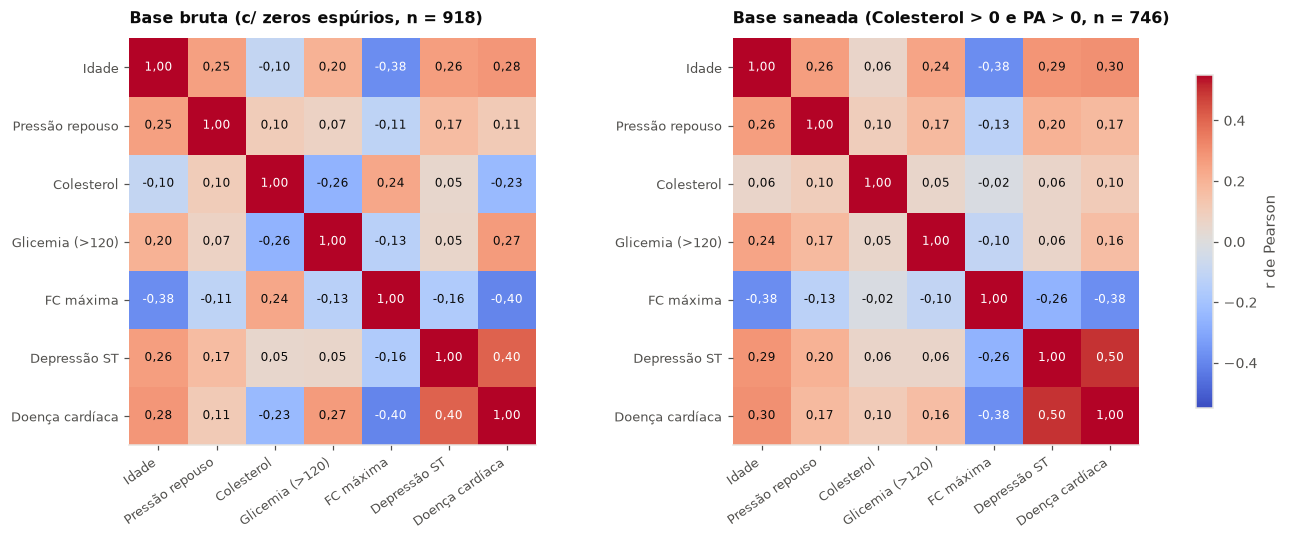

,r na base bruta (n = 918),r na base saneada (n = 746),Diferença (saneada − bruta)
Depressão ST,0.404,0.496,0.092
Idade,0.282,0.299,0.017
Pressão repouso,0.108,0.173,0.065
Glicemia (>120),0.267,0.161,-0.106
Colesterol,-0.233,0.104,0.337
FC máxima,-0.400,-0.377,0.023


In [33]:
df_num = pd.DataFrame({
    "Idade": df["idade"],
    "Pressão repouso": df["pressao_repouso"],
    "Colesterol": df["colesterol"],
    "Glicemia (>120)": (df["glicemia_jejum"] == "> 120 mg/dL (1)").astype(int),
    "FC máxima": df["freq_cardiaca_max"],
    "Depressão ST": df["depressao_st"],
    "Doença cardíaca": (df["doenca_cardiaca"] == "Com doença (1)").astype(int),
})

mascara_limpa = (df["colesterol"] > 0) & (df["pressao_repouso"] > 0)
corr_bruta = df_num.corr().round(3)
corr_limpa = df_num.loc[mascara_limpa].corr().round(3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.8), layout="constrained")
for ax, mat, tit in [
    (ax1, corr_bruta, "Base bruta (c/ zeros espúrios, n = 918)"),
    (ax2, corr_limpa, "Base saneada (Colesterol > 0 e PA > 0, n = 746)"),
]:
    im = ax.imshow(mat.values, cmap="coolwarm", vmin=-0.55, vmax=0.55)
    ax.set_xticks(range(len(mat.columns)), mat.columns, rotation=35, ha="right", fontsize=8.5)
    ax.set_yticks(range(len(mat.index)), mat.index, fontsize=8.5)
    ax.grid(False)
    ax.set_title(tit, fontsize=10.5, pad=10)
    for i in range(len(mat.index)):
        for j in range(len(mat.columns)):
            val = mat.values[i, j]
            cor_txt = "white" if abs(val) > 0.32 else TEXTO
            ax.text(j, i, formatar_num(val, 2), ha="center", va="center", fontsize=8, color=cor_txt)

fig.colorbar(im, ax=[ax1, ax2], shrink=0.82, label="r de Pearson")
plt.show()

print("Comparação das correlações de Pearson com a variável-alvo (Doença cardíaca):")
comp_corr = pd.DataFrame({
    "r na base bruta (n = 918)": corr_bruta["Doença cardíaca"],
    "r na base saneada (n = 746)": corr_limpa["Doença cardíaca"],
    "Diferença (saneada − bruta)": (corr_limpa["Doença cardíaca"] - corr_bruta["Doença cardíaca"]).round(3),
}).drop(index="Doença cardíaca").sort_values("r na base saneada (n = 746)", ascending=False)
display(comp_corr)

### 8.2 Interações de segunda ordem entre atributos categóricos

Redes neurais com camadas ocultas não lineares destacam-se quando a combinação de dois ou mais atributos altera a probabilidade do alvo além da soma marginal de cada um. Abaixo examinamos três interações clínicas de alto impacto:

1. **Tipo de dor no peito × Angina no exercício:** pacientes **Assintomáticos (`ASY`)** que desenvolvem angina durante o teste ergométrico (`Sim`) atingem **90,24% de doença cardíaca ($n = 297$)**! Mesmo quando **não** têm angina no exercício, pacientes `ASY` ainda têm **62,31% ($n = 199$)**. Já pacientes com **Angina atípica (`ATA`)** sem angina no esforço têm apenas **9,62% ($n = 156$)**, mas saltam para **52,94%** se apresentarem angina no teste;
2. **Inclinação de ST × Tipo de dor no peito:** a combinação de inclinação **Plana (`Flat`)** ou **Descendente (`Down`)** com quadro **Assintomático (`ASY`)** eleva a taxa de doença para **90,88% ($n = 318$)** e **91,30% ($n = 46$)**, respectivamente — ao passo que inclinação **Ascendente (`Up`)** em pacientes não-ASY reduz o risco para **6,46% ($n = 263$)**;
3. **Sexo × Tipo de dor no peito:** entre as mulheres, quadros de `ATA`, `TA` e `NAP` têm prevalência muito baixa (**6,67% a 11,32%**), mas mulheres com quadro `ASY` saltam para **55,71% ($n = 70$)** (e homens `ASY` chegam a **82,86%, $n = 426$**).

Tabela 1 — Tipo de dor no peito × Angina induzida por exercício:
Tabela 2 — Inclinação do segmento ST × Tipo de dor no peito:


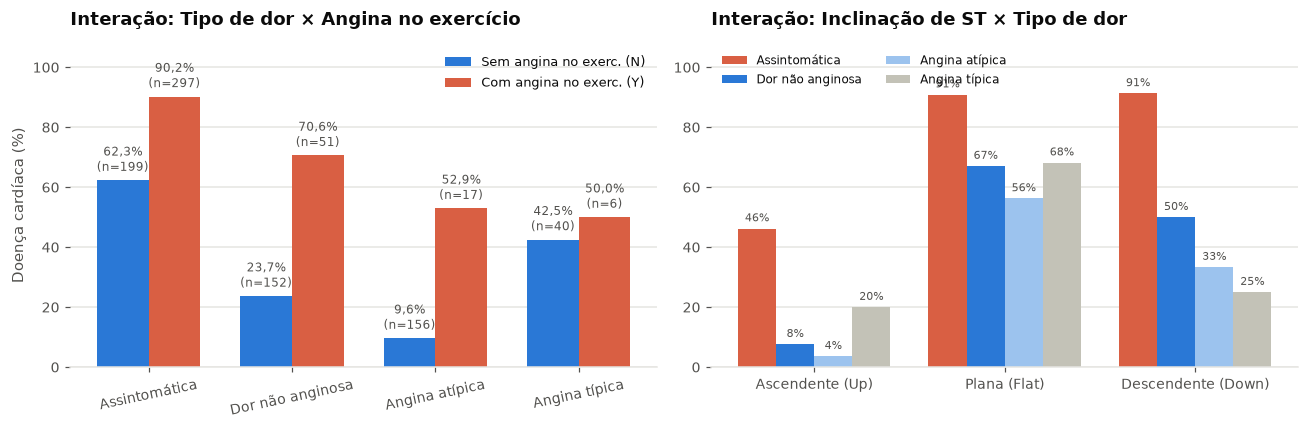

,Não (N) — Taxa (%),Não (N) — (pos/total),Sim (Y) — Taxa (%),Sim (Y) — (pos/total)
tipo_dor_peito,,,,
Assintomática (ASY),62.31,124/199,90.24,268/297
Dor não anginosa (NAP),23.68,36/152,70.59,36/51
Angina atípica (ATA),9.62,15/156,52.94,9/17
Angina típica (TA),42.50,17/40,50.00,3/6


,Assintomática (ASY) — Taxa (%),Assintomática (ASY) — (pos/total),Dor não anginosa (NAP) — Taxa (%),Dor não anginosa (NAP) — (pos/total),Angina atípica (ATA) — Taxa (%),Angina atípica (ATA) — (pos/total),Angina típica (TA) — Taxa (%),Angina típica (TA) — (pos/total)
inclinacao_st,,,,,,,,
Ascendente (Up),46.21,61/132,7.62,8/105,3.62,5/138,20.00,4/20
Plana (Flat),90.88,289/318,67.05,59/88,56.25,18/32,68.18,15/22
Descendente (Down),91.30,42/46,50.00,5/10,33.33,1/3,25.00,1/4


In [34]:
def tabela_interacao(df, col_linha, col_coluna, ordem_l=None, ordem_c=None):
    tot = pd.crosstab(df[col_linha], df[col_coluna])
    pos = pd.crosstab(
        df.loc[df["doenca_cardiaca"] == "Com doença (1)", col_linha],
        df.loc[df["doenca_cardiaca"] == "Com doença (1)", col_coluna],
    ).reindex(index=tot.index, columns=tot.columns, fill_value=0)
    taxa = (pos / tot * 100).round(2)
    if ordem_l is not None:
        tot = tot.reindex(ordem_l)
        pos = pos.reindex(ordem_l)
        taxa = taxa.reindex(ordem_l)
    if ordem_c is not None:
        tot = tot.reindex(columns=ordem_c)
        pos = pos.reindex(columns=ordem_c)
        taxa = taxa.reindex(columns=ordem_c)

    resumo = pd.DataFrame(index=tot.index)
    for c in tot.columns:
        resumo[f"{c} — Taxa (%)"] = taxa[c]
        resumo[f"{c} — (pos/total)"] = [f"{p}/{t}" for p, t in zip(pos[c], tot[c])]
    return taxa, tot, resumo

taxa_dor_ang, tot_dor_ang, res_dor_ang = tabela_interacao(
    df, "tipo_dor_peito", "angina_exercicio",
    ordem_l=ordem_classes("tipo_dor_peito"), ordem_c=ordem_classes("angina_exercicio"),
)

taxa_st_dor, tot_st_dor, res_st_dor = tabela_interacao(
    df, "inclinacao_st", "tipo_dor_peito",
    ordem_l=ordem_classes("inclinacao_st"), ordem_c=ordem_classes("tipo_dor_peito"),
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.0, 4.0))

# Painel 1: Tipo de dor x Angina no exercício
x1 = np.arange(len(taxa_dor_ang.index))
w1 = 0.36
b_nao = ax1.bar(x1 - w1/2, taxa_dor_ang["Não (N)"].values, width=w1, color=AZUL, label="Sem angina no exerc. (N)")
b_sim = ax1.bar(x1 + w1/2, taxa_dor_ang["Sim (Y)"].values, width=w1, color=CORAL, label="Com angina no exerc. (Y)")
ax1.set_xticks(x1, [c.split(" (")[0] for c in taxa_dor_ang.index], rotation=12)
ax1.set_ylim(0, 108)
ax1.grid(axis="x", visible=False)
ax1.set_ylabel("Doença cardíaca (%)")
ax1.set_title("Interação: Tipo de dor × Angina no exercício")
ax1.legend(loc="upper right", fontsize=8.5)
for barras, col_c in [(b_nao, "Não (N)"), (b_sim, "Sim (Y)")]:
    for b, t, n_t in zip(barras, taxa_dor_ang[col_c].values, tot_dor_ang[col_c].values):
        ax1.text(b.get_x() + b.get_width()/2, t + 1.8, f"{formatar_pct(t)}\n(n={n_t})",
                 ha="center", va="bottom", fontsize=7.8, color=TEXTO_SEC)

# Painel 2: Inclinação ST x Tipo de dor
x2 = np.arange(len(taxa_st_dor.index))
w2 = 0.20
cores_dor = [CORAL, AZUL, AZUL_CLARO, CINZA_OUTROS]
for idx_c, (col_c, cor_c) in enumerate(zip(taxa_st_dor.columns, cores_dor)):
    desloc = (idx_c - 1.5) * w2
    barras = ax2.bar(x2 + desloc, taxa_st_dor[col_c].values, width=w2, color=cor_c, label=col_c.split(" (")[0])
    for b, t in zip(barras, taxa_st_dor[col_c].values):
        ax2.text(b.get_x() + b.get_width()/2, t + 1.5, formatar_pct(t, 0),
                 ha="center", va="bottom", fontsize=7.5, color=TEXTO_SEC)
ax2.set_xticks(x2, list(taxa_st_dor.index))
ax2.set_ylim(0, 108)
ax2.grid(axis="x", visible=False)
ax2.set_title("Interação: Inclinação de ST × Tipo de dor")
ax2.legend(loc="upper left", fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

print("Tabela 1 — Tipo de dor no peito × Angina induzida por exercício:")
display(res_dor_ang)
print("Tabela 2 — Inclinação do segmento ST × Tipo de dor no peito:")
display(res_st_dor)

### 8.3 Interações contínuas: `idade × freq_cardiaca_max` e `freq_cardiaca_max × depressao_st`

Os dois gráficos de dispersão abaixo ilustram a separação das classes no espaço contínuo bidimensional:
- No plano **Idade × Frequência cardíaca máxima**, a frequência cardíaca declina com a idade em ambos os grupos, mas a reta de tendência dos pacientes **Com doença (1)** mantém-se sistematicamente **$15\text{ a }20\text{ bpm}$ abaixo** da reta dos pacientes **Sem doença (0)** em todas as faixas etárias;
- No plano **Frequência cardíaca máxima × Depressão de ST (`Oldpeak`)**, observa-se uma clara concentração dos pacientes saudáveis no quadrante superior esquerdo ($\text{FC}_{\max} > 140\text{ bpm}$ e $\text{Oldpeak} = 0$), enquanto os pacientes cardiopatas dominam a região de $\text{FC}_{\max} < 140\text{ bpm}$ e/ou $\text{Oldpeak} \ge 1,0\text{ mV}$.

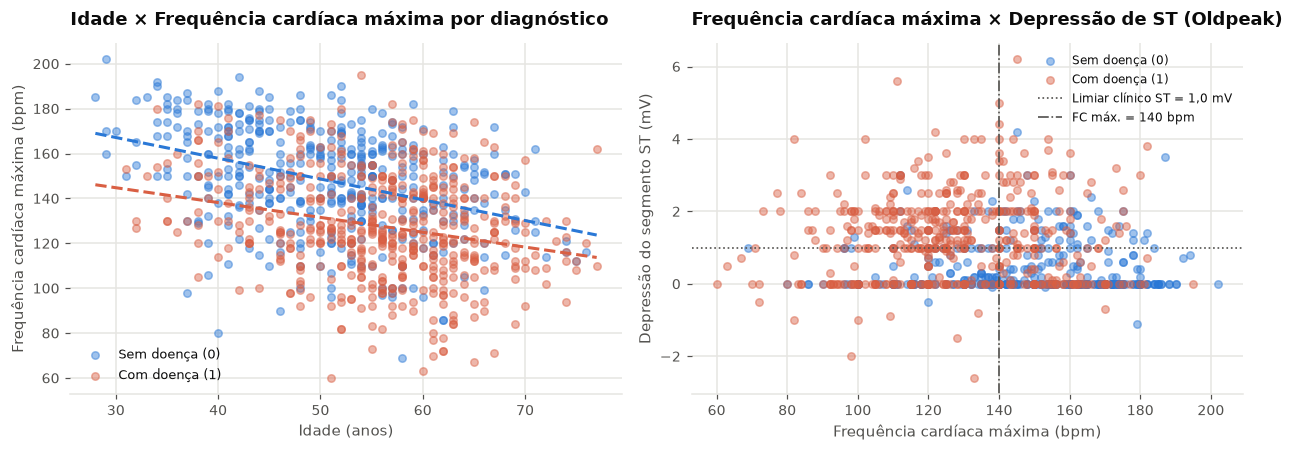

,Pacientes (n),Com doença (n),Taxa de doença (%)
Região no plano (FC máx. × Oldpeak),,,
"Baixo risco ergométrico (FC máx. ≥ 140 bpm e 0 ≤ Oldpeak < 1,0 mV)",289,72,24.91
Risco intermediário (apenas um dos critérios alterado),355,198,55.77
"Alto risco ergométrico (FC máx. < 140 bpm e [Oldpeak ≥ 1,0 ou < 0 mV])",274,238,86.86


In [35]:
sem_d = df["doenca_cardiaca"] == "Sem doença (0)"
com_d = df["doenca_cardiaca"] == "Com doença (1)"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))

# Dispersão 1: Idade x FC máxima
ax1.scatter(df.loc[sem_d, "idade"], df.loc[sem_d, "freq_cardiaca_max"],
            color=AZUL, alpha=0.45, s=24, label="Sem doença (0)")
ax1.scatter(df.loc[com_d, "idade"], df.loc[com_d, "freq_cardiaca_max"],
            color=CORAL, alpha=0.45, s=24, label="Com doença (1)")

x_grid = np.linspace(df["idade"].min(), df["idade"].max(), 100)
for mask_g, cor_g, rot_g in [(sem_d, AZUL, "Tendência Sem doença"), (com_d, CORAL, "Tendência Com doença")]:
    coef = np.polyfit(df.loc[mask_g, "idade"], df.loc[mask_g, "freq_cardiaca_max"], 1)
    ax1.plot(x_grid, np.polyval(coef, x_grid), color=cor_g, linewidth=2.0, linestyle="--")

ax1.set_title("Idade × Frequência cardíaca máxima por diagnóstico")
ax1.set_xlabel("Idade (anos)")
ax1.set_ylabel("Frequência cardíaca máxima (bpm)")
ax1.legend(loc="lower left", fontsize=8.5)

# Dispersão 2: FC máxima x Depressão de ST
ax2.scatter(df.loc[sem_d, "freq_cardiaca_max"], df.loc[sem_d, "depressao_st"],
            color=AZUL, alpha=0.45, s=24, label="Sem doença (0)")
ax2.scatter(df.loc[com_d, "freq_cardiaca_max"], df.loc[com_d, "depressao_st"],
            color=CORAL, alpha=0.45, s=24, label="Com doença (1)")
ax2.axhline(1.0, color=TEXTO_SEC, linestyle=":", linewidth=1.1, label="Limiar clínico ST = 1,0 mV")
ax2.axvline(140, color=TEXTO_SEC, linestyle="-.", linewidth=1.1, label="FC máx. = 140 bpm")
ax2.set_title("Frequência cardíaca máxima × Depressão de ST (Oldpeak)")
ax2.set_xlabel("Frequência cardíaca máxima (bpm)")
ax2.set_ylabel("Depressão do segmento ST (mV)")
ax2.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

resumo_quadrantes = pd.DataFrame([
    {
        "Região no plano (FC máx. × Oldpeak)": "Baixo risco ergométrico (FC máx. ≥ 140 bpm e 0 ≤ Oldpeak < 1,0 mV)",
        "Pacientes (n)": int(((df["freq_cardiaca_max"] >= 140) & (df["depressao_st"] >= 0) & (df["depressao_st"] < 1.0)).sum()),
        "Com doença (n)": int(((df["freq_cardiaca_max"] >= 140) & (df["depressao_st"] >= 0) & (df["depressao_st"] < 1.0) & com_d).sum()),
        "Taxa de doença (%)": round(
            com_d[(df["freq_cardiaca_max"] >= 140) & (df["depressao_st"] >= 0) & (df["depressao_st"] < 1.0)].mean() * 100, 2
        ),
    },
    {
        "Região no plano (FC máx. × Oldpeak)": "Risco intermediário (apenas um dos critérios alterado)",
        "Pacientes (n)": int((((df["freq_cardiaca_max"] < 140) ^ ((df["depressao_st"] >= 1.0) | (df["depressao_st"] < 0)))).sum()),
        "Com doença (n)": int((((df["freq_cardiaca_max"] < 140) ^ ((df["depressao_st"] >= 1.0) | (df["depressao_st"] < 0))) & com_d).sum()),
        "Taxa de doença (%)": round(
            com_d[((df["freq_cardiaca_max"] < 140) ^ ((df["depressao_st"] >= 1.0) | (df["depressao_st"] < 0)))].mean() * 100, 2
        ),
    },
    {
        "Região no plano (FC máx. × Oldpeak)": "Alto risco ergométrico (FC máx. < 140 bpm e [Oldpeak ≥ 1,0 ou < 0 mV])",
        "Pacientes (n)": int(((df["freq_cardiaca_max"] < 140) & ((df["depressao_st"] >= 1.0) | (df["depressao_st"] < 0))).sum()),
        "Com doença (n)": int(((df["freq_cardiaca_max"] < 140) & ((df["depressao_st"] >= 1.0) | (df["depressao_st"] < 0)) & com_d).sum()),
        "Taxa de doença (%)": round(
            com_d[(df["freq_cardiaca_max"] < 140) & ((df["depressao_st"] >= 1.0) | (df["depressao_st"] < 0))].mean() * 100, 2
        ),
    },
]).set_index("Região no plano (FC máx. × Oldpeak)")
display(resumo_quadrantes)

## 9. Síntese dos achados e diretrizes para a modelagem com Redes Neurais

### 9.1 Resumo dos principais achados da EDA

1. **Alvo moderadamente balanceado:** `55,34%` com doença cardíaca ($508$) e `44,66%` sem doença ($410$). A acurácia e a ROC-AUC são bem comportadas, mas vale monitorar sensibilidade (*recall* da classe positiva, crucial em triagem médica), especificidade e F1.
2. **Hierarquia de preditores:**
   - **Muito fortes:** `inclinacao_st` ($V = 0,623$), `tipo_dor_peito` ($V = 0,540$), `angina_exercicio` ($V = 0,492$), `depressao_st` ($r_{pb} = +0,404$, subindo a $+0,496$ na base limpa) e `freq_cardiaca_max` ($r_{pb} = -0,400$);
   - **Moderados:** `sexo` ($V = 0,303$), `idade` ($r_{pb} = +0,282$) e `glicemia_jejum` ($V = 0,265$);
   - **Fracos isoladamente (mas úteis em interações/extremos):** `pressao_repouso` ($r_{pb} = +0,118$), `ecg_repouso` ($V = 0,109$) e `colesterol` válido ($r_{pb} = +0,104$).
3. **Ausentes ocultos e Paradoxo de Simpson no colesterol:** há **172 registros com `colesterol == 0` (18,74%)** e **1 registro com `pressao_repouso == 0` (0,11%)**. Como os zeros de colesterol vêm das coortes da Suíça ($100\%$ de zeros e $93,5\%$ de doentes) e de Long Beach VA ($24,5\%$ de zeros e $74,5\%$ de doentes), a taxa de doença nos pacientes com `colesterol == 0` é de **88,37%** (contra **47,72%** quando `colesterol > 0`), o que inverte artificialmente o sinal da correlação do colesterol bruto ($r = -0,233$ vs. $r = +0,104$ nos valores válidos).

---

### 9.2 Implicações diretas para Redes Neurais Artificiais (MLP)

Diferentemente das árvores de decisão e *Random Forests* (que são invariantes a transformações monotônicas de escala e conseguem isolar `colesterol == 0` com um único corte $\text{colesterol} \le 42,5$), **Redes Neurais Artificiais calculam combinações lineares $z = \mathbf{w}^\top \mathbf{x} + b$ otimizadas por gradiente descendente**, sendo altamente sensíveis à escala, à presença de zeros artificiais e a caudas extremas:

| Aspecto | Problema identificado na EDA | Recomendação para o pipeline da Rede Neural |
| :--- | :--- | :--- |
| **1. Zeros espúrios em `Cholesterol` (172) e `RestingBP` (1)** | Manter `0` distorce a média/DP do `StandardScaler` e mistura ausência de coleta com valor numérico extremo ($-4,1\sigma$). Remover as 172 linhas descarta $18,7\%$ da base. | Substituir `0` por `NaN` em `Cholesterol` e `RestingBP`, criar a coluna binária **`colesterol_ausente` (`0/1`)** e **imputar o valor contínuo** (mediana ou `KNNImputer`, ajustado **apenas no treino** de cada fold). Isso preserva a escala fisiológica e mantém o forte sinal preditivo da coorte! |
| **2. Escalonamento de variáveis contínuas** | As unidades variam de $[-2,6; 6,2]\text{ mV}$ (`Oldpeak`) a $[85; 603]\text{ mg/dL}$ (`Cholesterol`), com caudas positivas em `Cholesterol`, `Oldpeak` e `RestingBP`. | Aplicar **`StandardScaler`** ou **`RobustScaler`** (ou transformação logarítmica/Yeo-Johnson antes da padronização) em `Age`, `RestingBP`, `Cholesterol`, `MaxHR` e `Oldpeak` dentro do `ColumnTransformer`. |
| **3. Valores negativos em `Oldpeak` (13 casos)** | Representam elevação de ST ($69,2\%$ de doença), enquanto `Oldpeak == 0` tem $33,7\%$ e `Oldpeak >= 1` tem $> 72\%$. | Manter os valores reais e avaliar nos experimentos uma flag binária auxiliar (`oldpeak_negativo` ou `oldpeak_zero`) para facilitar a separação não monotônica em arquiteturas rasas. |
| **4. Codificação de categóricas** | 3 binárias (`Sex`, `FastingBS`, `ExerciseAngina`) e 3 multiclasse (`ChestPainType` [4], `RestingECG` [3], `ST_Slope` [3]). | Mapear binárias para `{0, 1}` (ou `{-1, +1}`) e aplicar **`OneHotEncoder`** nas multiclasse, resultando em **18 a 20 features numéricas bem condicionadas** na camada de entrada. |
| **5. Tamanho amostral ($n = 918$)** | Base tabular compacta: redes profundas com muitas centenas de pesos memorizam rapidamente o conjunto de treino. | Priorizar arquiteturas MLP enxutas (1 a 2 camadas ocultas, ex.: `16` a `64` neurônios), regularização **$L_2$ (*weight decay*)**, ***Dropout*** moderado ($0,1\text{ a }0,3$) e ***Early Stopping*** guiado por validação cruzada estratificada. |